**[Keith Phang] · [25034227]**

# 6FTC2175 AMLNN — Coursework 1: SmartFactory Predictive Quality Control
### Classical ML vs Feed-Forward Neural Network vs Convolutional Neural Network

SmartFactory wants to catch faulty production **before** it reaches the customer. This notebook builds and compares three models:

| Part | Data | Model | Module lessons applied |
|---|---|---|---|
| **A** | AI4I 2020 sensor readings (tabular) | **Random Forest** (classical) | Lesson 1 (bagging, Random Forest, boosting), Lesson 2 (SVM, Naive Bayes, model comparison) |
| **A** | same | **Feed-forward NN (MLP)** | Lesson 3 (MLP, backpropagation), Lesson 4 (loss, metrics, capacity, regularisation) |
| **B** | Casting product images | **CNN trained from scratch** | Lesson 5 (convolution, pooling, filters, feature maps, augmentation, dropout, GAP) |
| **C** | — | **Comparison + deployment recommendation** | all lessons |

**Positive class (1) = the faulty case** everywhere: *machine failure* in Part A, *defective casting* in Part B. All decisions (model choice, hyper-parameters,
decision threshold) are made on **validation** data; each **test** set is used **once**, at the end of its part.


---
## Step 0 — Setup (shared by all parts)

In [ ]:
!pip install -q ucimlrepo kagglehub

In [ ]:
import os, time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, precision_recall_curve, roc_curve)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)      # seeds Python, NumPy and TensorFlow (as in Lessons 4 and 5)
plt.rcParams["figure.figsize"] = (7, 4)

NOTEBOOK_START = time.time()
SECTION_TIMES = {}
print("TensorFlow", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0
GPU available: True


### Shared evaluation helpers
Both datasets are **imbalanced** in the sense that matters: a missed fault is far more costly than a false alarm, and in Part A only ~3.4% of runs fail.
It shows that **accuracy can mislead** (the *accuracy paradox*), so every model is scored with the same panel, always for the positive (faulty) class:

| Metric | Meaning for SmartFactory |
|---|---|
| **Recall** = TP/(TP+FN) | share of real faults caught — a missed fault reaches the customer or damages the machine |
| **Precision** = TP/(TP+FP) | share of alarms that are real — false alarms waste inspections and stop the line |
| **F1** | balance of precision and recall at the chosen threshold |
| **PR-AUC** (average precision) | threshold-free; more informative than ROC-AUC when the positive class is rare |
| **ROC-AUC** | threshold-free ranking quality (Lesson 4, Step 2c) |
| **MCC** | one number using all four confusion-matrix cells; robust to imbalance |

**Decision threshold:** 0.5 is a choice, not a law. We pick the threshold that maximises F1 **on validation data** and apply it unchanged to the test set.

In [ ]:
def best_threshold(y_true, proba):
    # threshold that maximises F1 on the data given (always call this on VALIDATION data)
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p * r / (p + r + 1e-12)
    i = int(np.nanargmax(f1[:-1]))
    return float(t[i])

def evaluate(y_true, proba, threshold, name):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"Model": name, "Threshold": round(threshold, 3),
            "Precision": precision_score(y_true, pred, zero_division=0), "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred), "PR-AUC": average_precision_score(y_true, proba),
            "ROC-AUC": roc_auc_score(y_true, proba), "MCC": matthews_corrcoef(y_true, pred),
            "Balanced acc": balanced_accuracy_score(y_true, pred), "Accuracy": accuracy_score(y_true, pred),
            "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}

def threshold_table(y_true, proba, thresholds):
    rows = []
    for t in thresholds:
        p_t = (proba >= t).astype(int)
        rows.append({"threshold": round(t, 3), "precision": precision_score(y_true, p_t, zero_division=0),
                     "recall": recall_score(y_true, p_t), "F1": f1_score(y_true, p_t),
                     "missed faults (FN)": int(((p_t == 0) & (y_true == 1)).sum()),
                     "false alarms (FP)": int(((p_t == 1) & (y_true == 0)).sum())})
    return pd.DataFrame(rows).round(3)

def bootstrap_ci(y_true, proba, threshold, n=1000, seed=RANDOM_STATE):
    # 95% confidence intervals for test F1 and PR-AUC by resampling the test set
    rng = np.random.default_rng(seed); f1s, aps = [], []
    pred = (proba >= threshold).astype(int)
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].sum() == 0: continue
        f1s.append(f1_score(y_true[i], pred[i])); aps.append(average_precision_score(y_true[i], proba[i]))
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(aps, [2.5, 97.5])

def plot_curves(histories, metrics=("loss", "pr_auc"), titles=("Loss (binary cross-entropy)", "PR-AUC")):
    # Lesson 5 style: solid = training, dashed = validation, one colour per model
    fig, axes = plt.subplots(1, len(metrics), figsize=(6.5 * len(metrics), 4))
    for label, h in histories.items():
        ep = range(1, len(h["loss"]) + 1)
        for ax, m in zip(axes, metrics):
            line, = ax.plot(ep, h[m], label=f"{label} – train")
            ax.plot(ep, h["val_" + m], "--", color=line.get_color(), label=f"{label} – val")
    for ax, t in zip(axes, titles):
        ax.set(title=t, xlabel="epoch"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

def conv_params(k, c_in, c_out): return k * k * c_in * c_out + c_out     # Lesson 5 formula
def dense_params(n_in, n_out):   return n_in * n_out + n_out              # Lesson 4 formula

### Experimental protocol — how every split is used (applies to all three models)

| Split | Part A (AI4I, 10,000 runs) | Part B (casting images) | What it is used for |
|---|---|---|---|
| **Training** | 70% (7,000 rows, stratified) | ~70% of the 7,348 pooled images, **split by casting group** (Step B3) | fitting weights / trees; cross-validation and out-of-bag estimates for model family and hyper-parameter choices |
| **Validation** | 15% (1,500 rows, stratified) | ~15%, by group | early stopping, choosing the architecture / configuration, the decision threshold and the cost-based threshold, robustness checks used for deployment |
| **Test** | 15% (1,500 rows, stratified) | ~15%, by group | **once**, after every decision is frozen |
| **External** | — | second export `casting_512x512` (1,300 images) | reporting only: generalisation to a different export; never used to tune anything |

Rules followed throughout: no decision is taken on test data; the scaler is fitted on training data only; feature-engineering formulas come from the
dataset documentation (fixed *before* modelling, not tuned on results); the same random seed (42) is used everywhere; the decision threshold is chosen on validation
data and applied unchanged to test data.

In [ ]:
# Environment record — copy these versions into the README / report appendix for reproducibility
import sys, platform, sklearn
print("Python", sys.version.split()[0], "|", platform.platform())
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| tensorflow", tf.__version__, "| keras", keras.__version__)

DETERMINISTIC = False   # True = bit-for-bit repeatable TensorFlow runs (slower, especially on GPU)
if DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()
print("Seed", RANDOM_STATE, "| deterministic TF ops:", DETERMINISTIC)

Python 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39
numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | tensorflow 2.21.0 | keras 3.13.2
Seed 42 | deterministic TF ops: False


---
# PART A — Tabular sensor data: Random Forest vs Feed-forward NN

**Dataset:** *AI4I 2020 Predictive Maintenance* (UCI ML Repository, id 601; Matzka, 2020). 10,000 production runs of a milling machine, each with
five process sensor readings, a product quality variant (L / M / H) and a label: did the run end in **machine failure**?

## Step A1 — Load the data

In [ ]:
t_A = time.time()

def load_ai4i():
    try:
        from ucimlrepo import fetch_ucirepo
        df = fetch_ucirepo(id=601).data.original
        print("Loaded from the UCI repository")
    except Exception as e:                                   # fallback: upload the Kaggle CSV yourself
        print("UCI download failed:", e, "-> please upload ai4i2020.csv")
        from google.colab import files
        up = files.upload(); df = pd.read_csv(next(iter(up)))
    df.columns = [c.split(" [")[0].strip() for c in df.columns]   # drop unit suffixes such as ' [K]'
    return df.rename(columns={"UDI": "UID"})

df = load_ai4i()
TARGET = "Machine failure"
num_cols = ["Air temperature", "Process temperature", "Rotational speed", "Torque", "Tool wear"]
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
df.head()

Loaded from the UCI repository
Shape: (10000, 14) | missing values: 0 | duplicate rows: 0


,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step A2 — Explore: class balance and the accuracy paradox

Machine failure
pass (0)    9661
fail (1)     339

Failure rate: 3.39%
A model that ALWAYS predicts 'pass' scores accuracy 0.966 — and catches 0 failures (recall 0).


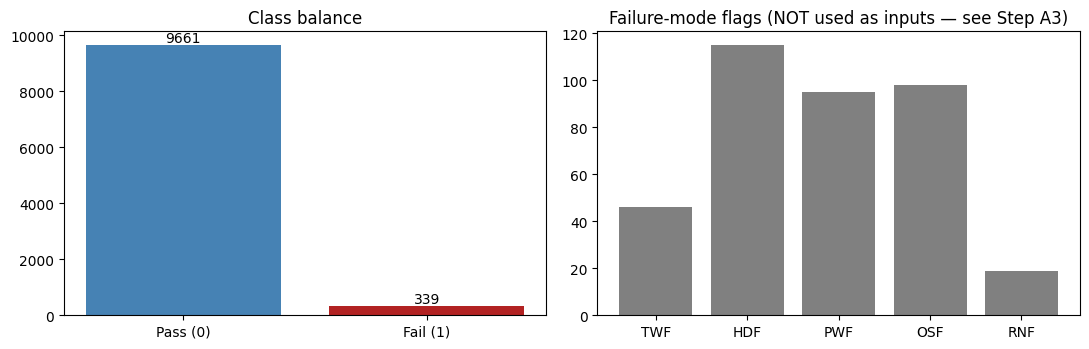

In [ ]:
counts = df[TARGET].value_counts().sort_index()
print(counts.rename({0: "pass (0)", 1: "fail (1)"}).to_string())
print(f"\nFailure rate: {counts[1] / counts.sum():.2%}")
print(f"A model that ALWAYS predicts 'pass' scores accuracy {counts[0] / counts.sum():.3f} — and catches 0 failures (recall 0).")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(["Pass (0)", "Fail (1)"], counts.values, color=["steelblue", "firebrick"])
for i, v in enumerate(counts.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set_title("Class balance")
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
ax[1].bar(modes, df[modes].sum().values, color="grey")
ax[1].set_title("Failure-mode flags (NOT used as inputs — see Step A3)")
plt.tight_layout(); plt.show()

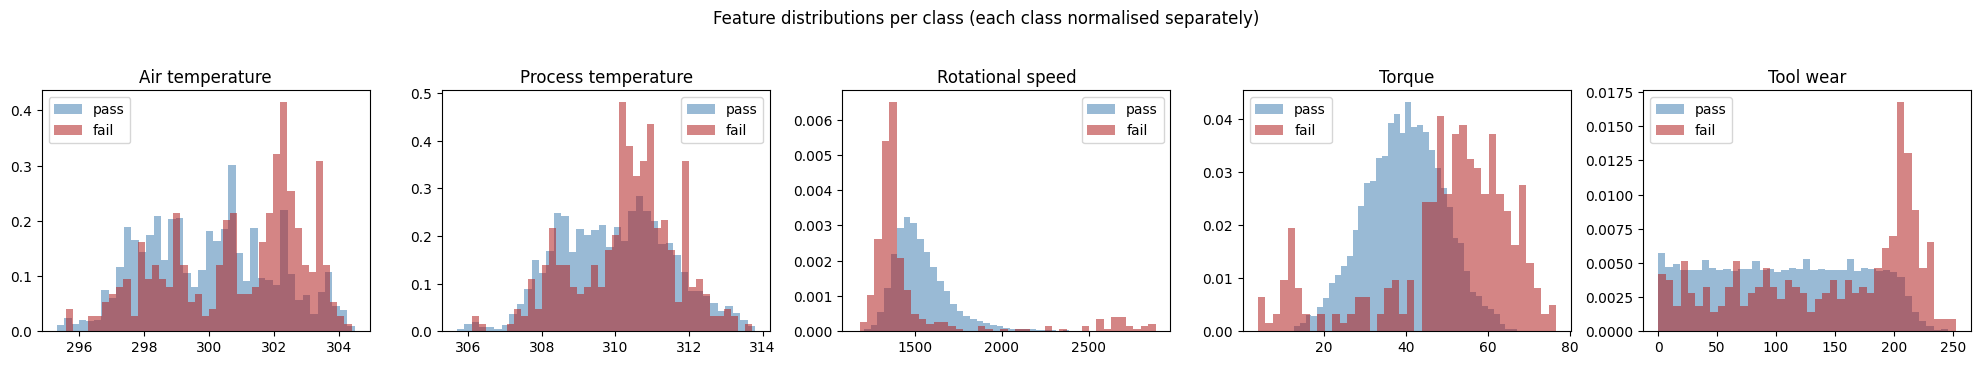

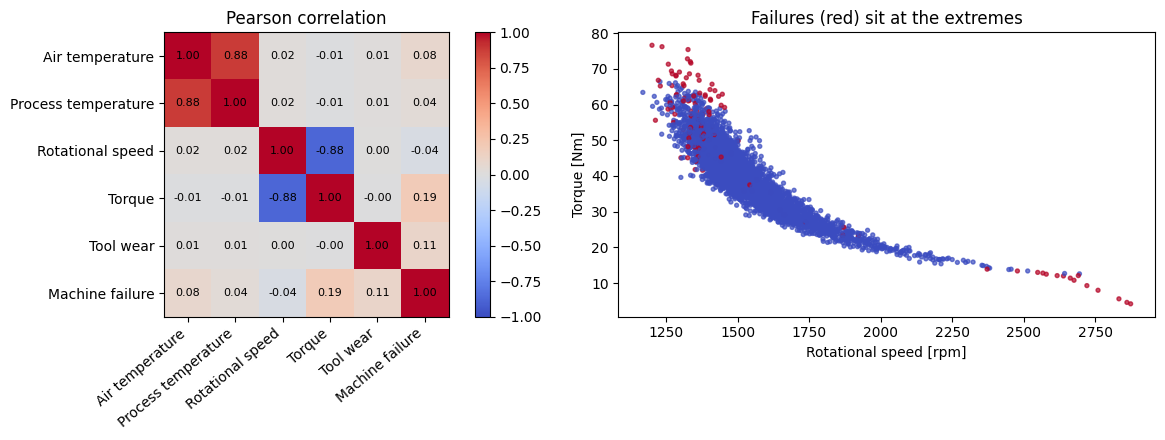

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, c in zip(axes, num_cols):
    for lbl, colour in [(0, "steelblue"), (1, "firebrick")]:
        ax.hist(df.loc[df[TARGET] == lbl, c], bins=40, density=True, alpha=0.55, color=colour,
                label="fail" if lbl else "pass")
    ax.set_title(c); ax.legend()
plt.suptitle("Feature distributions per class (each class normalised separately)", y=1.03); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
corr = df[num_cols + [TARGET]].corr()
im = ax[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(corr))); ax[0].set_xticklabels(corr.columns, rotation=40, ha="right")
ax[0].set_yticks(range(len(corr))); ax[0].set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): ax[0].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[0].set_title("Pearson correlation"); plt.colorbar(im, ax=ax[0])
s = df.sample(4000, random_state=RANDOM_STATE)
ax[1].scatter(s["Rotational speed"], s["Torque"], c=s[TARGET], cmap="coolwarm", s=8, alpha=0.7)
ax[1].set(xlabel="Rotational speed [rpm]", ylabel="Torque [Nm]", title="Failures (red) sit at the extremes")
plt.tight_layout(); plt.show()

**Observations**
- Only ~3.4% of runs fail → accuracy is useless as a headline metric (always-"pass" scores ~96.6%).
- Torque and rotational speed are strongly negatively correlated (≈ −0.88). Failures sit at **extreme combinations** of torque/speed and at **high tool wear**:
  the boundary is **non-linear** and driven by **interactions**. Single-feature correlations with the target are weak.
  This already argues against linear models and against Naive Bayes' independence assumption.

## Step A3 — Preprocessing

**1. Remove identifiers and leaking columns.**
`UID` and `Product ID` are identifiers. `TWF, HDF, PWF, OSF, RNF` are the five failure-mode flags; `Machine failure` is defined as *any of them = 1*, and they are
only known **after** the failure. Keeping them would give a near-perfect but useless model (**data leakage**).

**2. Physically motivated feature engineering.** The dataset documentation describes how failures arise, so we encode three mechanisms:
- **Power [W]** = torque × angular speed (2π·rpm/60) → *power failure* outside a power band
- **Temp diff [K]** = process − air temperature → *heat-dissipation failure* when it is small at low speed
- **Strain** = tool wear × torque → *overstrain failure*

**3. One-hot encode** the quality variant `Type` (L / M / H).

In [ ]:
def build_features(data, engineered=True):
    X = pd.get_dummies(data[["Type"] + num_cols], columns=["Type"], prefix="Type", dtype=float)
    if engineered:
        X["Power"] = X["Torque"] * X["Rotational speed"] * 2 * np.pi / 60
        X["Temp diff"] = X["Process temperature"] - X["Air temperature"]
        X["Strain"] = X["Tool wear"] * X["Torque"]
    return X

y = df[TARGET].astype(int).values
X_raw, X_eng = build_features(df, engineered=False), build_features(df, engineered=True)
feat_names = list(X_eng.columns)
print("Inputs used:", feat_names)

Inputs used: ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Type_H', 'Type_L', 'Type_M', 'Power', 'Temp diff', 'Strain']


**4. Stratified train / validation / test split (70 / 15 / 15).** Stratified so every split keeps the 3.4% failure rate. Validation is used for model selection,
early stopping and the decision threshold; the **test set is locked away until Step A7** and is the same for both models.

**5. Scaling.** The Random Forest needs none (trees split on thresholds, so rescaling changes nothing). The MLP needs it: rpm is in the thousands, torque in tens —
unscaled inputs give badly conditioned gradients (Lesson 3, Step 3). `StandardScaler` is **fitted on the training set only**.

In [ ]:
idx = np.arange(len(df))
idx_trval, idx_test = train_test_split(idx, test_size=0.15, stratify=y, random_state=RANDOM_STATE)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.15 / 0.85, stratify=y[idx_trval], random_state=RANDOM_STATE)
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

def split(X):
    X = X.values.astype(np.float32)
    return X[idx_train], X[idx_val], X[idx_test]

Xr_train, Xr_val, Xr_test = split(X_raw)
Xe_train, Xe_val, Xe_test = split(X_eng)
scaler = StandardScaler().fit(Xe_train)                               # fit on TRAINING data only
Xs_train, Xs_val, Xs_test = (scaler.transform(a).astype(np.float32) for a in (Xe_train, Xe_val, Xe_test))

assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}: n={len(part):5d}   failures={part.sum():3d}   rate={part.mean():.2%}")
print("Splits are disjoint; the SAME idx_test rows are used for every Part A model.")

train: n= 7000   failures=237   rate=3.39%
val  : n= 1500   failures= 51   rate=3.40%
test : n= 1500   failures= 51   rate=3.40%
Splits are disjoint; the SAME idx_test rows are used for every Part A model.


## Step A4 — Choosing the classical model (Lessons 1 and 2)

I test one representative of each family on the **same** folds, with **5-fold stratified cross-validation on
the training set**, scored by PR-AUC (No single model wins everywhere, so compare on *this* data).

Baseline: a single, fully-grown decision tree, to see its variance.

In [ ]:
tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xe_train, y_train)
print(f"Single decision tree — train F1 {f1_score(y_train, tree.predict(Xe_train)):.3f} | "
      f"validation F1 {f1_score(y_val, tree.predict(Xe_val)):.3f}   -> large gap = high variance (Lesson 1, Step 4)")

Single decision tree — train F1 1.000 | validation F1 0.817   -> large gap = high variance (Lesson 1, Step 4)


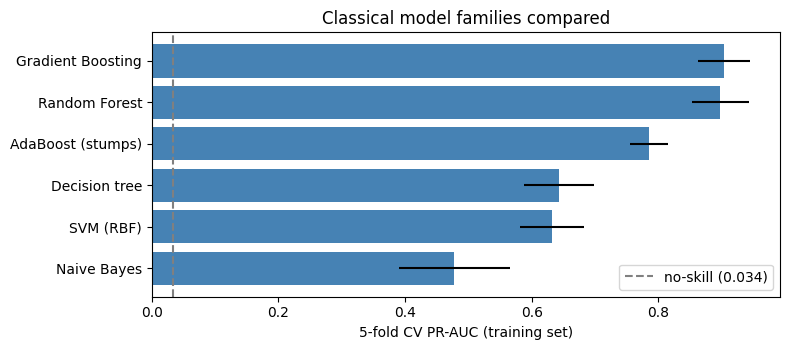

,Model,CV PR-AUC (mean),± std,time (s)
4,Gradient Boosting,0.904,0.041,19.250
5,Random Forest,0.898,0.045,11.053
3,AdaBoost (stumps),0.785,0.030,12.562
0,Decision tree,0.643,0.055,3.803
2,SVM (RBF),0.632,0.051,1.950
1,Naive Bayes,0.478,0.088,0.108


In [ ]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "Decision tree":      DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive Bayes":        make_pipeline(StandardScaler(), GaussianNB()),
    "SVM (RBF)":          make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale",
                                                              class_weight="balanced", random_state=RANDOM_STATE)),
    "AdaBoost (stumps)":  AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting":  GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=RANDOM_STATE),
    "Random Forest":      RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}
rows = []
for name, model in candidates.items():
    t0 = time.time()
    s = cross_val_score(model, Xe_train, y_train, cv=cv5, scoring="average_precision", n_jobs=-1)
    rows.append({"Model": name, "CV PR-AUC (mean)": s.mean(), "± std": s.std(), "time (s)": time.time() - t0})
family = pd.DataFrame(rows).sort_values("CV PR-AUC (mean)", ascending=False).round(3)

plt.figure(figsize=(8, 3.6))
plt.barh(family["Model"], family["CV PR-AUC (mean)"], xerr=family["± std"], color="steelblue")
plt.axvline(y_train.mean(), ls="--", c="grey", label=f"no-skill ({y_train.mean():.3f})")
plt.gca().invert_yaxis(); plt.xlabel("5-fold CV PR-AUC (training set)"); plt.title("Classical model families compared"); plt.legend()
plt.tight_layout(); plt.show()
family

**Reading the comparison**
- **Naive Bayes** is weakest: it assumes features are independent given the class, which is clearly false (torque and speed correlate at ≈ −0.88), and its smooth
  Gaussian boundary cannot carve out the small "extreme-combination" failure regions.
- **SVM (RBF)** draws smooth margins but struggles here: failures are few, scattered regions in several dimensions, and the SVM gives no native probabilities.
- A **single tree** is unstable (high variance). **AdaBoost** on stumps is limited by very weak learners.
- **Random Forest** and **Gradient Boosting** are clearly best and statistically tied (difference well inside one standard deviation).

**Choice: Random Forest.** At equal accuracy we prefer it because (1) bagging trains trees **in parallel and independently**, so it is faster to train and easy to scale;
(2) it is **less sensitive to hyper-parameters** than boosting (no learning-rate / number-of-rounds trade-off to tune, Lesson 1 Step 9); (3) it gives a free **out-of-bag**
validation estimate; (4) feature importances support interpretability. Its axis-aligned splits suit threshold-like failure rules (e.g. *tool wear > 200 min and torque high*).

### Iteration 1 — raw vs engineered features

In [ ]:
# Ablation: add each engineered feature to the 8 raw inputs on its own, then all three together (5-fold CV on training data)
rf_default = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
raw_idx = list(range(8))
ablation_sets = {"raw only (8)": raw_idx,
                 "raw + Power": raw_idx + [feat_names.index("Power")],
                 "raw + Temp diff": raw_idx + [feat_names.index("Temp diff")],
                 "raw + Strain": raw_idx + [feat_names.index("Strain")],
                 "raw + all three (11)": list(range(11))}
rows = []
for label, cols in ablation_sets.items():
    sc = cross_val_score(rf_default, Xe_train[:, cols], y_train, cv=cv5, scoring="average_precision", n_jobs=-1)
    rows.append({"feature set": label, "CV PR-AUC": sc.mean(), "± std": sc.std()})
ablation = pd.DataFrame(rows)
ablation["gain vs raw"] = ablation["CV PR-AUC"] - ablation.loc[0, "CV PR-AUC"]
ablation.round(3)

,feature set,CV PR-AUC,± std,gain vs raw
0,raw only (8),0.771,0.057,0.000
1,raw + Power,0.849,0.041,0.077
2,raw + Temp diff,0.829,0.043,0.057
3,raw + Strain,0.837,0.064,0.065
4,raw + all three (11),0.898,0.045,0.127


**Reading the ablation.** Each engineered feature is tested on its own, so the gain can be attributed. The features add information the trees find hard to build from
axis-aligned splits: *power* is a **product** of torque and speed (a curved boundary in the speed–torque plane that would otherwise need many small rectangular splits) and
*temp diff* is a **difference** of two inputs (a diagonal boundary). The gains are several times larger than the fold-to-fold standard deviation, so they are not noise.
Both models use the engineered set from here on; Step A6 checks the same question for the MLP.

## Step A5 — Random Forest: how many trees, then tuning

### Iteration 2 — number of trees, using the free out-of-bag (OOB) estimate
Each tree never sees ~37% of the training rows (they are not in its bootstrap sample). Scoring every row only with the trees that did not see it gives an honest
validation estimate **without** using the validation set.

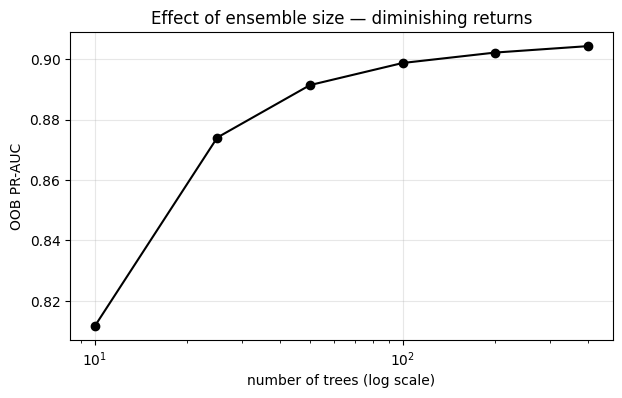

,n_estimators,OOB accuracy,OOB PR-AUC
0,10,0.9904,0.8116
1,25,0.9914,0.8741
2,50,0.9920,0.8914
3,100,0.9924,0.8988
4,200,0.9923,0.9022
5,400,0.9929,0.9043


In [ ]:
rows = []
for n in [10, 25, 50, 100, 200, 400]:
    m = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1).fit(Xe_train, y_train)
    p = m.oob_decision_function_[:, 1]; ok = ~np.isnan(p)
    rows.append({"n_estimators": n, "OOB accuracy": m.oob_score_, "OOB PR-AUC": average_precision_score(y_train[ok], p[ok])})
oob = pd.DataFrame(rows)
plt.plot(oob["n_estimators"], oob["OOB PR-AUC"], marker="o", color="black")
plt.xscale("log"); plt.xlabel("number of trees (log scale)"); plt.ylabel("OOB PR-AUC")
plt.title("Effect of ensemble size — diminishing returns"); plt.grid(alpha=0.3); plt.show()
oob.round(4)

Gains flatten after roughly 100–200 trees. OOB **accuracy** barely moves at all because it is dominated by the 96.6% easy
"pass" cases — another illustration of why we track PR-AUC. We fix **200 trees**.

### Iteration 3 — tuning tree depth, leaf size and features per split (grid search, 3-fold CV, PR-AUC)
- `max_depth` / `min_samples_leaf` control how much each tree can memorise (variance).
- `max_features` controls how decorrelated the trees are (`"sqrt"` = classic Random Forest; `None` = plain bagging of trees).

In [ ]:
grid = GridSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    {"max_depth": [8, None], "min_samples_leaf": [1, 8], "max_features": ["sqrt", None]},
    scoring="average_precision", cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
t0 = time.time(); grid.fit(Xe_train, y_train)
print(f"Grid search: {time.time() - t0:.0f}s | best CV PR-AUC {grid.best_score_:.3f} | best params {grid.best_params_}")
(pd.DataFrame(grid.cv_results_)[["param_max_depth", "param_min_samples_leaf", "param_max_features", "mean_test_score", "std_test_score"]]
   .sort_values("mean_test_score", ascending=False).round(3))

Grid search: 47s | best CV PR-AUC 0.916 | best params {'max_depth': 8, 'max_features': None, 'min_samples_leaf': 8}


,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_score,std_test_score
3,8,8,None,0.916,0.023
2,8,1,None,0.914,0.028
7,None,8,None,0.914,0.023
6,None,1,None,0.908,0.029
0,8,1,sqrt,0.900,0.030
4,None,1,sqrt,0.899,0.032
5,None,8,sqrt,0.892,0.031
1,8,8,sqrt,0.889,0.034


In [ ]:
rf = RandomForestClassifier(n_estimators=200, **grid.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time(); rf.fit(Xe_train, y_train); rf_train_time = time.time() - t0

rf_val_proba = rf.predict_proba(Xe_val)[:, 1]
rf_thr = best_threshold(y_val, rf_val_proba)
print(f"Fit time {rf_train_time:.2f}s | validation PR-AUC {average_precision_score(y_val, rf_val_proba):.3f} | "
      f"train PR-AUC {average_precision_score(y_train, rf.predict_proba(Xe_train)[:, 1]):.3f}")
print(f"F1-optimal threshold on validation: {rf_thr:.3f}\n")
print("Moving the threshold (validation set, Lesson 4 Step 2b):")
threshold_table(y_val, rf_val_proba, [0.1, 0.2, 0.3, 0.5, 0.7, rf_thr])

Fit time 3.52s | validation PR-AUC 0.873 | train PR-AUC 0.964
F1-optimal threshold on validation: 0.319

Moving the threshold (validation set, Lesson 4 Step 2b):


,threshold,precision,recall,F1,missed faults (FN),false alarms (FP)
0,0.100,0.623,0.843,0.717,8,26
1,0.200,0.837,0.804,0.820,10,8
2,0.300,0.932,0.804,0.863,10,3
3,0.500,1.000,0.725,0.841,14,0
4,0.700,1.000,0.725,0.841,14,0
5,0.319,0.932,0.804,0.863,10,3


Lowering the threshold catches more failures (recall ↑) at the cost of more false alarms (precision ↓). Where to sit on that trade-off is a **business decision**:
if a missed failure costs far more than an inspection, SmartFactory should choose a lower threshold than the F1-optimal one.

## Step A6 — Feed-forward neural network (MLP)

**Design (applies to every network below)**
- 11 standardised inputs → hidden **ReLU** layers (cheap, no vanishing gradient for positive inputs) → **1 sigmoid** output = P(fail).
- **Loss: binary cross-entropy** — the right pairing for a sigmoid output. It heavily punishes *confident mistakes*.
- **Optimiser: Adam**, learning rate 1e-3 (Adam converges fastest without tuning). Batch size 128.
- Training = **backpropagation**: the chain rule gives ∂loss/∂w for every weight, layer by layer, and Adam uses those gradients to update the weights.

### Iteration 1 — capacity: underfit, good fit, overfit
Three networks of very different size, trained for a fixed 100 epochs with **no** regularisation, so the learning curves show the effect of capacity alone.
We monitor validation **PR-AUC** as well as loss: with 96.6% "pass" rows the loss is dominated by easy cases, while PR-AUC tracks how well failures are ranked.

Tiny [4]               11 → 4 → 1: parameters by hand =     53 | Keras =     53 | 34.5s
Medium [32,16]   11 → 32 → 16 → 1: parameters by hand =    929 | Keras =    929 | 32.7s
Large [128,64]   11 → 128 → 64 → 1: parameters by hand =  9,857 | Keras =  9,857 | 32.1s


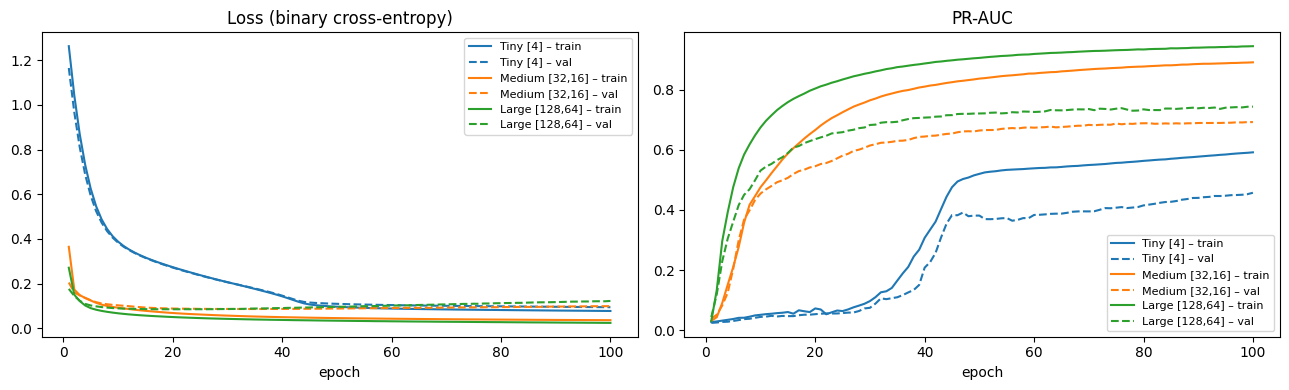

In [ ]:
N_FEAT = Xs_train.shape[1]

def make_mlp(hidden, dropout=0.0, l2=0.0, n_in=None):
    model = keras.Sequential([keras.Input(shape=(n_in or N_FEAT,))])
    for units in hidden:
        reg = keras.regularizers.l2(l2) if l2 > 0 else None
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    return model

def run_mlp(cfg, X_tr=None, y_tr=None, X_va=None, seed=RANDOM_STATE, y_va=None):
    X_tr = Xs_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_va = Xs_val if X_va is None else X_va
    y_va = y_val if y_va is None else y_va
    keras.utils.set_random_seed(seed)
    model = make_mlp(cfg["hidden"], cfg.get("dropout", 0.0), cfg.get("l2", 0.0), n_in=X_tr.shape[1])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(curve="PR", name="pr_auc")])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=25, restore_best_weights=True)] if cfg.get("early_stop") else []
    cw = None
    if cfg.get("class_weight") == "balanced":
        w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr); cw = {0: w[0], 1: w[1]}
    t0 = time.time()
    h = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=cfg["epochs"], batch_size=128,
                  class_weight=cw, callbacks=cbs, verbose=0).history
    return model, h, time.time() - t0

def params_by_hand(sizes):
    return sum(dense_params(a, b) for a, b in zip(sizes[:-1], sizes[1:]))

mlp_configs = {
    "Tiny [4]":        dict(hidden=[4], epochs=100),
    "Medium [32,16]":  dict(hidden=[32, 16], epochs=100),
    "Large [128,64]":  dict(hidden=[128, 64], epochs=100),
}
mlp_runs = {name: run_mlp(cfg) for name, cfg in mlp_configs.items()}
for name, cfg in mlp_configs.items():
    sizes = [N_FEAT, *cfg["hidden"], 1]
    print(f"{name:16s} {' → '.join(map(str, sizes)):>16}: parameters by hand = {params_by_hand(sizes):6,d} | "
          f"Keras = {mlp_runs[name][0].count_params():6,d} | {mlp_runs[name][2]:.1f}s")
plot_curves({n: r[1] for n, r in mlp_runs.items()})

**How to read these curves**
- **Tiny:** training and validation PR-AUC stay low and close together → **underfitting** (high bias): 4 hidden units cannot represent the interaction regions.
- **Large:** training PR-AUC keeps climbing while validation PR-AUC flattens or drops and validation loss turns upward → **overfitting** (high variance):
  with only ~240 failures in the training set, 9,000+ weights can memorise them.
- **Medium** sits in between.

### Iteration 2 — fixing overfitting: L2 + dropout + early stopping
We keep the **large** network (enough capacity) and add all three remedies from the lecture: **L2 weight decay** (λ = 1e-4), **dropout** (0.3) and
**early stopping** (patience 25 epochs on validation PR-AUC, best weights restored).

### Iteration 3 — handling imbalance in the loss: class weights
So far the imbalance is handled only by the threshold. Alternatively, `class_weight="balanced"` multiplies the loss of each failure by ≈ 15 so the
rare class dominates the gradient. We test whether that helps.

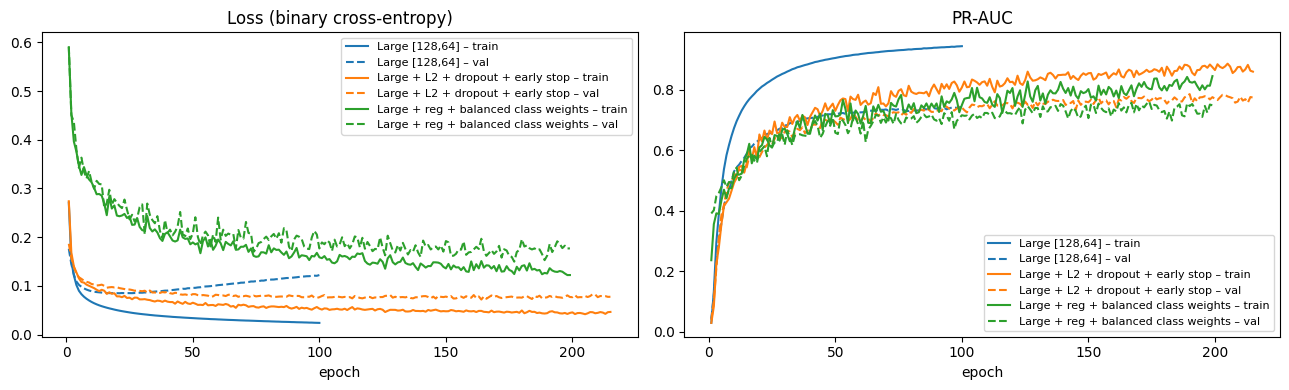

,MLP,params,epochs run,best epoch,train PR-AUC (final),val PR-AUC (model kept),val ROC-AUC,train time (s)
0,Tiny [4],53,100,100,0.591,0.458,0.910,34.519
1,"Medium [32,16]",929,100,100,0.891,0.701,0.922,32.710
2,"Large [128,64]",9857,100,100,0.945,0.749,0.916,32.083
3,Large + L2 + dropout + early stop,9857,215,190,0.860,0.786,0.939,67.923
4,Large + reg + balanced class weights,9857,199,174,0.846,0.765,0.937,62.402


In [ ]:
mlp_configs.update({
    "Large + L2 + dropout + early stop":        dict(hidden=[128, 64], dropout=0.3, l2=1e-4, epochs=300, early_stop=True),
    "Large + reg + balanced class weights":     dict(hidden=[128, 64], dropout=0.3, l2=1e-4, epochs=300, early_stop=True, class_weight="balanced"),
})
for name in list(mlp_configs)[3:]:
    mlp_runs[name] = run_mlp(mlp_configs[name])

plot_curves({n: mlp_runs[n][1] for n in ["Large [128,64]", "Large + L2 + dropout + early stop", "Large + reg + balanced class weights"]})

rows = []
for name, (model, h, secs) in mlp_runs.items():
    vp = model.predict(Xs_val, verbose=0).ravel()
    best = int(np.argmax(h["val_pr_auc"]))
    rows.append({"MLP": name, "params": model.count_params(), "epochs run": len(h["loss"]), "best epoch": best + 1,
                 "train PR-AUC (final)": h["pr_auc"][-1], "val PR-AUC (model kept)": average_precision_score(y_val, vp),
                 "val ROC-AUC": roc_auc_score(y_val, vp), "train time (s)": secs})
mlp_table = pd.DataFrame(rows).round(3)
mlp_table

**Reading the table**
- Regularisation closes much of the train–validation gap of the large network and early stopping saves wasted epochs.
- Balanced class weights make every failure count ~15× in the loss. This stops the network ignoring the rare class, but makes each gradient step noisy
  (a handful of samples dominate) and pushes probabilities upward. Because we already tune the threshold on validation data, they do not necessarily help —
  the table shows whether they did on this data.
- Note: with dropout, the *training* curve is computed with units switched off, so it can sit below the validation curve; compare trends, not absolute levels.

**Selection rule:** the network with the highest validation PR-AUC (validation data only).

In [ ]:
best_mlp_name = mlp_table.sort_values("val PR-AUC (model kept)", ascending=False).iloc[0]["MLP"]
mlp, mlp_hist, mlp_train_time = mlp_runs[best_mlp_name]
mlp_val_proba = mlp.predict(Xs_val, verbose=0).ravel()
mlp_thr = best_threshold(y_val, mlp_val_proba)
print("Selected MLP:", best_mlp_name, f"| F1-optimal validation threshold = {mlp_thr:.3f}")
mlp.summary()

Selected MLP: Large + L2 + dropout + early stop | F1-optimal validation threshold = 0.234


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,573 (115.52 KB)

 Trainable params: 9,857 (38.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,716 (77.02 KB)

### Does feature engineering help the MLP too?
Same selected configuration, trained on the 8 raw inputs (with their own scaler fitted on training data) instead of the 11 engineered ones.

In [ ]:
scaler_raw = StandardScaler().fit(Xr_train)
mlp_raw, _, _ = run_mlp(mlp_configs[best_mlp_name], scaler_raw.transform(Xr_train).astype(np.float32), y_train,
                        X_va=scaler_raw.transform(Xr_val).astype(np.float32))
pd.DataFrame({"MLP input": ["raw features (8)", "engineered features (11)"],
              "val PR-AUC": [average_precision_score(y_val, mlp_raw.predict(scaler_raw.transform(Xr_val), verbose=0).ravel()),
                             average_precision_score(y_val, mlp_val_proba)]}).round(3)

,MLP input,val PR-AUC
0,raw features (8),0.770
1,engineered features (11),0.786


In principle an MLP can learn products and differences of its inputs by itself, so it should need feature engineering *less* than trees. With only ~240 failure examples,
however, handing it the physically meaningful combinations directly still helps: it does not have to discover them from scarce data.

## Step A7 — Test-set evaluation (held-out, used once)

In [ ]:
rf_test_proba = rf.predict_proba(Xe_test)[:, 1]
mlp_test_proba = mlp.predict(Xs_test, verbose=0).ravel()

t0 = time.time(); rf.predict_proba(Xe_test); rf_inf = (time.time() - t0) / len(y_test)
t0 = time.time(); mlp.predict(Xs_test, verbose=0, batch_size=2048); mlp_inf = (time.time() - t0) / len(y_test)

resA = pd.DataFrame([evaluate(y_test, rf_test_proba, rf_thr, "Random Forest"),
                     evaluate(y_test, mlp_test_proba, mlp_thr, "MLP")]).set_index("Model")
resA["Train time (s)"] = [rf_train_time, mlp_train_time]
resA["Inference (ms / sample)"] = [rf_inf * 1000, mlp_inf * 1000]
resA["Size (MB)"] = [len(pickle.dumps(rf)) / 1e6, mlp.count_params() * 4 / 1e6]
resA["Params / tree nodes"] = [sum(t.tree_.node_count for t in rf.estimators_), mlp.count_params()]
resA.T.round(3)

Model,Random Forest,MLP
Threshold,0.319,0.234
Precision,0.958,0.772
Recall,0.902,0.863
F1,0.929,0.815
PR-AUC,0.937,0.893
ROC-AUC,0.980,0.981
MCC,0.927,0.809
Balanced acc,0.950,0.927
Accuracy,0.995,0.987
TP,46.000,44.000


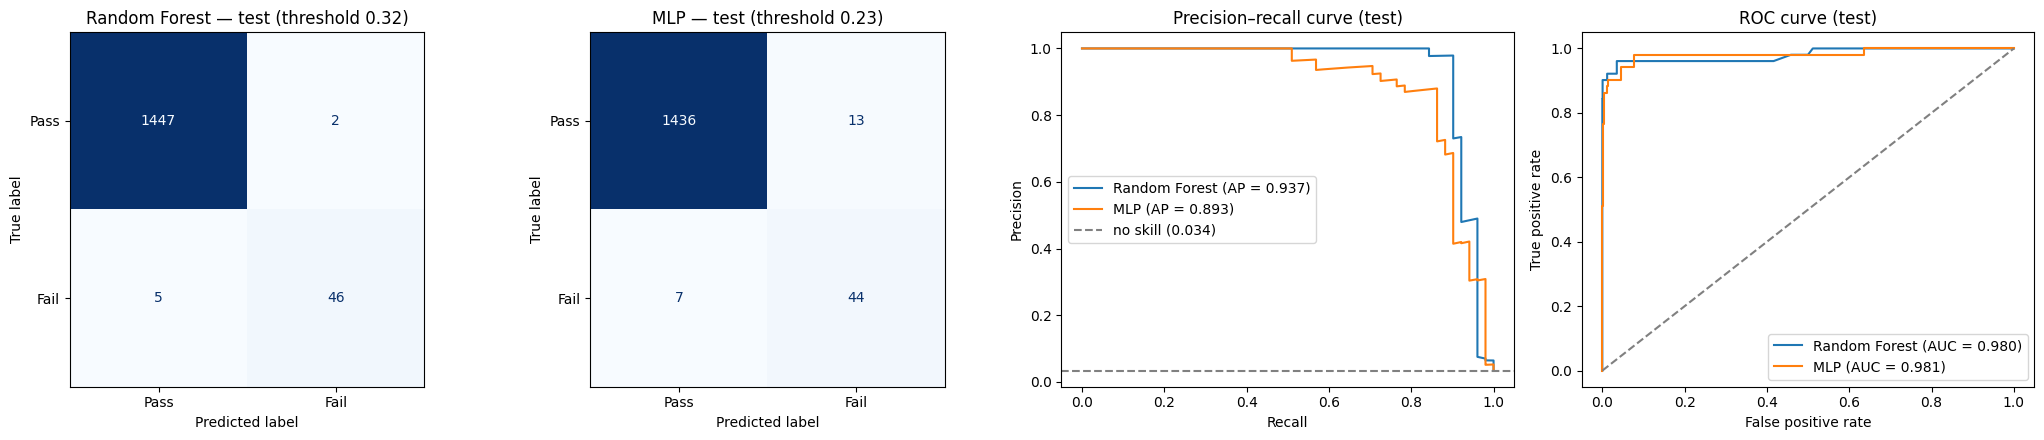

Random Forest  95% bootstrap CI:  F1 [0.869, 0.978]   PR-AUC [0.876, 0.988]
MLP            95% bootstrap CI:  F1 [0.729, 0.889]   PR-AUC [0.819, 0.954]


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, (name, proba, thr) in zip(axes[:2], [("Random Forest", rf_test_proba, rf_thr), ("MLP", mlp_test_proba, mlp_thr)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba >= thr).astype(int)), display_labels=["Pass", "Fail"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} — test (threshold {thr:.2f})")
for name, proba in [("Random Forest", rf_test_proba), ("MLP", mlp_test_proba)]:
    p, r, _ = precision_recall_curve(y_test, proba)
    axes[2].plot(r, p, label=f"{name} (AP = {average_precision_score(y_test, proba):.3f})")
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[3].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[2].axhline(y_test.mean(), ls="--", c="grey", label=f"no skill ({y_test.mean():.3f})")
axes[2].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve (test)"); axes[2].legend()
axes[3].plot([0, 1], [0, 1], ls="--", c="grey")
axes[3].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test)"); axes[3].legend()
plt.tight_layout(); plt.show()

for name, proba, thr in [("Random Forest", rf_test_proba, rf_thr), ("MLP", mlp_test_proba, mlp_thr)]:
    (f_lo, f_hi), (a_lo, a_hi) = bootstrap_ci(y_test, proba, thr)
    print(f"{name:14s} 95% bootstrap CI:  F1 [{f_lo:.3f}, {f_hi:.3f}]   PR-AUC [{a_lo:.3f}, {a_hi:.3f}]")

### Is the difference between the two models real?
Both models are scored on **exactly the same 1,500 test rows** (`idx_test`), the scaler was fitted on training rows only, and no tuning used test rows. Three checks:
1. **McNemar's test** — a *paired* test on the same rows: it ignores rows where both models are right or both wrong and looks only at the discordant rows
   (*b* = RF right / MLP wrong, *c* = RF wrong / MLP right). If the models were equally accurate, b and c would be equally likely (exact binomial version, suitable for small
   counts). It compares overall **classification errors**, not failure-class recall specifically, and a small p-value says the difference is unlikely to be chance — **not**
   that it is large enough to matter operationally; that is judged from the confusion matrices and costs (Part C).
2. **Seed variance:** retrain each final configuration with different random seeds. Each seed chooses its own threshold on validation, then is scored on test. A model whose
   result swings between seeds is less reliable to deploy.
3. **Paired cross-validation (below):** the same 5 folds of the training set for both models — mean ± standard deviation of PR-AUC and the per-fold difference.

In [ ]:
from scipy.stats import binomtest
rf_pred, mlp_pred = (rf_test_proba >= rf_thr).astype(int), (mlp_test_proba >= mlp_thr).astype(int)
b = int(((rf_pred == y_test) & (mlp_pred != y_test)).sum()); c = int(((rf_pred != y_test) & (mlp_pred == y_test)).sum())
p_mcnemar = binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
print(f"McNemar: RF right & MLP wrong = {b} | RF wrong & MLP right = {c} | exact p-value = {p_mcnemar:.3f}")

rows = []
for seed in [0, 1, 2, 3, 4]:
    m = RandomForestClassifier(n_estimators=200, **grid.best_params_, random_state=seed, n_jobs=-1).fit(Xe_train, y_train)
    pv, pt = m.predict_proba(Xe_val)[:, 1], m.predict_proba(Xe_test)[:, 1]
    rows.append({"model": "Random Forest", "seed": seed, "test F1": f1_score(y_test, pt >= best_threshold(y_val, pv)),
                 "test PR-AUC": average_precision_score(y_test, pt)})
for seed in [0, 1, 2]:
    m, _, _ = run_mlp(mlp_configs[best_mlp_name], seed=seed)
    pv, pt = m.predict(Xs_val, verbose=0).ravel(), m.predict(Xs_test, verbose=0).ravel()
    rows.append({"model": "MLP", "seed": seed, "test F1": f1_score(y_test, pt >= best_threshold(y_val, pv)),
                 "test PR-AUC": average_precision_score(y_test, pt)})
seeds = pd.DataFrame(rows)
seeds.groupby("model")[["test F1", "test PR-AUC"]].agg(["mean", "std", "min", "max"]).round(3)

McNemar: RF right & MLP wrong = 14 | RF wrong & MLP right = 1 | exact p-value = 0.001


test F1                      test PR-AUC                     
                 mean    std    min    max        mean    std    min    max
model                                                                      
MLP             0.841  0.004  0.838  0.845       0.898  0.005  0.894  0.904
Random Forest   0.929  0.000  0.929  0.929       0.935  0.001  0.934  0.937

**Reading the results (our run).**
- **McNemar:** on 10 test rows only the RF was right, and on 1 row only the MLP was right (exact p = 0.012). On these 1,500 paired rows the difference in errors is therefore
  unlikely to be chance. *Operationally*, it amounts to 3 fewer missed failures and 6 fewer false alarms per 1,500 runs (confusion matrices above). Whether that matters is a
  cost question (Part C), not a statistical one.
- **Seeds:** the RF's test F1 was identical across 5 seeds (0.929, std < 0.001), because averaging 200 trees removes most of the randomness. The MLP varied from 0.830 to 0.851 across 3 seeds.
  For deployment, the RF is the more **reliable** model as well as the more accurate one.

### Paired 5-fold cross-validation and uncertainty in failure-class metrics
Each fold's held-out part is scored by both models. The MLP's early stopping uses an inner 15% split of the fold's *training* part (never the held-out fold), and its
scaler is refitted on that inner training part. Recall on 51 test failures is uncertain, so **Wilson 95% intervals** are given for test recall and precision.
*Caveat:* the RF's hyper-parameters were chosen by CV on these same training rows (Step A5), so its CV score is slightly optimistic.

In [ ]:
rows = []
for k, (tr_i, ho_i) in enumerate(cv5.split(Xe_train, y_train)):
    rf_k = RandomForestClassifier(n_estimators=200, **grid.best_params_, random_state=RANDOM_STATE, n_jobs=-1).fit(Xe_train[tr_i], y_train[tr_i])
    in_tr, in_es = train_test_split(tr_i, test_size=0.15, stratify=y_train[tr_i], random_state=RANDOM_STATE)
    sc_k = StandardScaler().fit(Xe_train[in_tr])
    mlp_k, _, _ = run_mlp(mlp_configs[best_mlp_name], sc_k.transform(Xe_train[in_tr]).astype(np.float32), y_train[in_tr],
                          X_va=sc_k.transform(Xe_train[in_es]).astype(np.float32), y_va=y_train[in_es])
    rows.append({"fold": k + 1, "failures in fold": int(y_train[ho_i].sum()),
                 "RF PR-AUC": average_precision_score(y_train[ho_i], rf_k.predict_proba(Xe_train[ho_i])[:, 1]),
                 "MLP PR-AUC": average_precision_score(y_train[ho_i], mlp_k.predict(sc_k.transform(Xe_train[ho_i]), verbose=0).ravel())})
cv_pairs = pd.DataFrame(rows); cv_pairs["RF − MLP"] = cv_pairs["RF PR-AUC"] - cv_pairs["MLP PR-AUC"]
print(cv_pairs.round(3).to_string(index=False))
print(f"\nRF  PR-AUC {cv_pairs['RF PR-AUC'].mean():.3f} ± {cv_pairs['RF PR-AUC'].std():.3f} | "
      f"MLP PR-AUC {cv_pairs['MLP PR-AUC'].mean():.3f} ± {cv_pairs['MLP PR-AUC'].std():.3f} | "
      f"RF higher in {int((cv_pairs['RF − MLP'] > 0).sum())} of 5 folds (mean difference {cv_pairs['RF − MLP'].mean():+.3f})")

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h
print()
for name in ["Random Forest", "MLP"]:
    r = resA.loc[name]; tp, fn, fp = int(r.TP), int(r.FN), int(r.FP)
    (rl, rh), (pl, ph) = wilson(tp, tp + fn), wilson(tp, tp + fp)
    print(f"{name:14s} test recall {tp}/{tp + fn} = {tp / (tp + fn):.3f} (95% CI {rl:.3f}–{rh:.3f}) | "
          f"precision {tp}/{tp + fp} = {tp / (tp + fp):.3f} (95% CI {pl:.3f}–{ph:.3f})")

 fold  failures in fold  RF PR-AUC  MLP PR-AUC  RF − MLP
    1                47      0.862       0.768     0.094
    2                47      0.921       0.536     0.385
    3                47      0.895       0.726     0.169
    4                48      0.949       0.840     0.109
    5                48      0.958       0.866     0.092

RF  PR-AUC 0.917 ± 0.040 | MLP PR-AUC 0.747 ± 0.131 | RF higher in 5 of 5 folds (mean difference +0.170)

Random Forest  test recall 46/51 = 0.902 (95% CI 0.790–0.957) | precision 46/48 = 0.958 (95% CI 0.860–0.988)
MLP            test recall 44/51 = 0.863 (95% CI 0.743–0.932) | precision 44/57 = 0.772 (95% CI 0.648–0.862)


**Reading the results (our run).**
- **Paired CV:** RF PR-AUC **0.917 ± 0.040** vs MLP **0.734 ± 0.114**. The RF was higher in **all 5 folds**, and the MLP's fold-to-fold spread is about 3× larger (one fold: 0.553).
  The gap is somewhat overstated here: the MLP trains on 85% of each fold (the rest is needed for early stopping), and the RF's hyper-parameters were tuned on these rows.
  Still, the direction agrees with the validation, test, seed and data-size evidence.
- **Uncertainty on 51 failures:** test recall is 46/51 = 0.90 (Wilson 95% CI 0.79–0.96) for the RF and 43/51 = 0.84 (0.72–0.92) for the MLP. The intervals **overlap**, so
  test recall on its own cannot separate the two models. The case for the RF rests on the *consistency* of all the checks, not on any single number.
- **Bootstrap intervals (Step A7)** answer: *if the test set had been a different random 1,500 runs from the same process, how much would F1 move?* RF [0.87, 0.98]
  vs MLP [0.76, 0.91]. The partial overlap says the same thing: a real but imprecisely measured advantage.

**Notes for interpretation**
- The test set has only **51 failures**, so one extra caught failure moves recall by ~2 points. The bootstrap intervals show how much of the gap between the models is real.
- ROC-AUC is high for both models because it is dominated by the many easy "pass" cases; the **PR curve** separates them much more clearly — a concrete example of why PR-AUC
  is preferred for rare positives.

## Step A8 — Interpretability: which inputs drive the predictions?
- **Random Forest:** built-in (Gini) importance — free, but biased toward continuous features with many split points.
- **Both models:** **permutation importance** on the test set — shuffle one column, measure how much PR-AUC drops. Model-agnostic, so it compares the two models fairly.

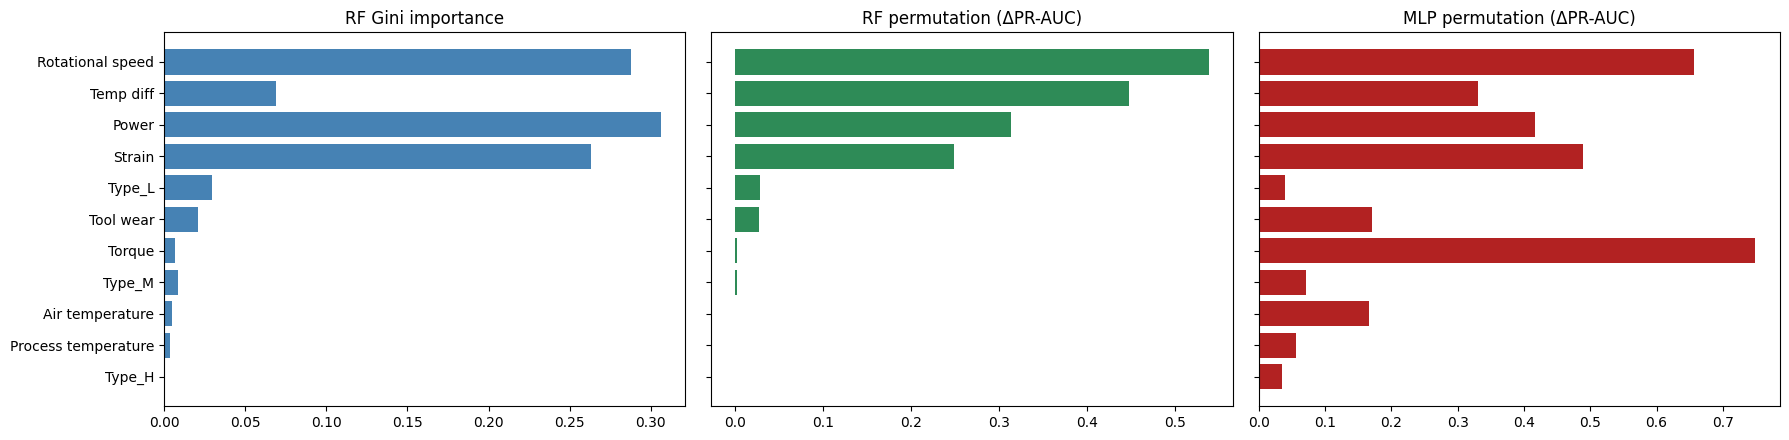

,RF Gini importance,RF permutation (ΔPR-AUC),MLP permutation (ΔPR-AUC)
Rotational speed,0.288,0.538,0.656
Temp diff,0.069,0.447,0.330
Power,0.306,0.314,0.417
Strain,0.263,0.248,0.489
Type_L,0.029,0.028,0.040
Tool wear,0.021,0.027,0.171
Torque,0.007,0.002,0.749
Type_M,0.008,0.002,0.072
Air temperature,0.005,-0.000,0.167
Process temperature,0.004,-0.000,0.056


In [ ]:
def perm_importance(predict_fn, X, y_true, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); base = average_precision_score(y_true, predict_fn(X))
    drops = []
    for j in range(X.shape[1]):
        d = []
        for _ in range(n_repeats):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            d.append(base - average_precision_score(y_true, predict_fn(Xp)))
        drops.append(np.mean(d))
    return np.array(drops)

imp = pd.DataFrame({
    "RF Gini importance": rf.feature_importances_,
    "RF permutation (ΔPR-AUC)": perm_importance(lambda X: rf.predict_proba(X)[:, 1], Xe_test, y_test),
    "MLP permutation (ΔPR-AUC)": perm_importance(lambda X: mlp.predict(X, verbose=0, batch_size=4096).ravel(), Xs_test, y_test),
}, index=feat_names).sort_values("RF permutation (ΔPR-AUC)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, col, c in zip(axes, imp.columns, ["steelblue", "seagreen", "firebrick"]):
    ax.barh(imp.index, imp[col], color=c); ax.set_title(col)
plt.tight_layout(); plt.show()
imp.sort_values("RF permutation (ΔPR-AUC)", ascending=False).round(3)

If both models rank the same **physical drivers** at the top (rotational speed / power, strain, temperature difference), they have learned real failure mechanisms
rather than noise. The Random Forest has the interpretability advantage: importances are built in and individual trees can be inspected; the MLP needs post-hoc tools.

## Step A9 — Data requirements: how much training data does each model need? (evidence for Part C)
We retrain both final configurations on 10%, 25%, 50% and 100% of the training set (stratified subsets) and score them on the **same validation set**.

In [ ]:
fractions = [0.1, 0.25, 0.5, 1.0]
rows = []
for frac in fractions:
    sub = np.arange(len(y_train)) if frac == 1.0 else train_test_split(
        np.arange(len(y_train)), train_size=frac, stratify=y_train, random_state=RANDOM_STATE)[0]
    m_rf = RandomForestClassifier(n_estimators=200, **grid.best_params_, random_state=RANDOM_STATE, n_jobs=-1).fit(Xe_train[sub], y_train[sub])
    m_mlp, _, _ = run_mlp(mlp_configs[best_mlp_name], Xs_train[sub], y_train[sub])
    rows.append({"fraction": frac, "training rows": len(sub), "training failures": int(y_train[sub].sum()),
                 "RF val PR-AUC": average_precision_score(y_val, m_rf.predict_proba(Xe_val)[:, 1]),
                 "MLP val PR-AUC": average_precision_score(y_val, m_mlp.predict(Xs_val, verbose=0).ravel())})
dataA = pd.DataFrame(rows)
SECTION_TIMES["Part A"] = time.time() - t_A
print(f"Part A finished in {SECTION_TIMES['Part A'] / 60:.1f} min")
dataA.round(3)

Part A finished in 18.2 min


,fraction,training rows,training failures,RF val PR-AUC,MLP val PR-AUC
0,0.10,700,24,0.619,0.495
1,0.25,1750,59,0.813,0.661
2,0.50,3500,119,0.837,0.729
3,1.00,7000,237,0.873,0.786


### Part A interpretation — *why* the Random Forest beats the MLP on this data (not just *that* it does)
1. **Shape of the decision rule.** The documented failure mechanisms are threshold rules (power outside a band, tool wear × torque above a limit, small temperature
   difference at low speed). A tree represents "*x > a and z > b*" with two splits; an MLP must approximate the same sharp corner with smooth combinations of ReLUs, which
   needs many examples near the boundary.
2. **Very few positive examples.** Only 237 training failures. The RF's bootstrap averaging is a strong variance-reducer (Lesson 1), whereas the MLP's 9,857 weights
   must be regularised hard (Step A6) and still overfit without it. The data-size curves above show the gap is **largest when data is scarce**.
3. **No scaling or architecture sensitivity.** The RF was insensitive to most hyper-parameters (grid search table); the MLP's result depended on capacity,
   regularisation, class weighting and random seed.
4. **Limitations of the MLP here, not in general:** with far more data, raw high-frequency sensor signals, or the need to learn representations (as in Part B),
   neural networks would be expected to scale better than trees.

---
# PART B — Images: a CNN trained from scratch (Lesson 5)

**Dataset:** *Real-life industrial dataset of casting product* (Kaggle, R. Dabhi, 2020): top-view photographs of cast submersible-pump impellers, labelled
**defective** (`def_front`) or **OK** (`ok_front`). The download contains two exports:
- `casting_data` — 7,348 images at 300×300, delivered by the author as `train/` and `test/` folders (the images were **augmented by the author before release**);
- `casting_512x512` — 1,300 images at 512×512, a second export. It is **never used for training, model selection or thresholds**; it is kept as an external test (Step B12).

**Why Part B does not use the author's train/test folders.** Step B2 shows that ~36% of the author's test images are rotated/mirrored/relit copies of castings that are
also in the author's training folder. A test set built like that partly measures memory. So, **before any training**, we pool the 7,348 images, group copies of the same
casting together, and split **by group** into training / validation / test (Step B3). Every model choice and threshold is then made on validation data, and the
grouped test set is used **once** (Step B9).

## Step B0 — Load the data

In [ ]:
t_B = time.time()
import glob, hashlib, kagglehub
from PIL import Image
root = kagglehub.dataset_download("ravirajsinh45/real-life-industrial-dataset-of-casting-product")
DATA_DIR = os.path.join(root, "casting_data", "casting_data")
EXT_DIR = os.path.join(root, "casting_512x512", "casting_512x512")

all_paths = np.array(sorted(glob.glob(os.path.join(DATA_DIR, "*", "*", "*.jpeg"))))
all_y = np.array([os.path.basename(os.path.dirname(p)) == "def_front" for p in all_paths]).astype(int)          # defective = 1
author_split = np.array([os.path.basename(os.path.dirname(os.path.dirname(p))) for p in all_paths])           # 'train' / 'test'
ext_paths = np.array(sorted(glob.glob(os.path.join(EXT_DIR, "*", "*.jpeg"))))
ext_y = np.array([os.path.basename(os.path.dirname(p)) == "def_front" for p in ext_paths]).astype(int)

print("Folders in the download:", sorted(os.listdir(root)), "| files other than images:",
      [f for f in glob.glob(os.path.join(root, "**", "*"), recursive=True) if os.path.isfile(f) and not f.endswith(".jpeg")])
pd.DataFrame({"author train/": pd.Series(all_y[author_split == "train"]).value_counts(),
              "author test/": pd.Series(all_y[author_split == "test"]).value_counts(),
              "second export (512×512)": pd.Series(ext_y).value_counts()}).rename(index={0: "OK (0)", 1: "defective (1)"})

Using Colab cache for faster access to the 'real-life-industrial-dataset-of-casting-product' dataset.
Folders in the download: ['casting_512x512', 'casting_data'] | files other than images: []


,author train/,author test/,second export (512×512)
defective (1),3758,453,781
OK (0),2875,262,519


**Grouping information.** The download contains only image files and two class folders: there are **no casting IDs, part IDs, batch IDs or capture dates** (the cell above
lists any non-image file it finds — none). Grouping therefore has to be reconstructed from the images themselves (Step B2–B3).

## Step B1 — Look at the data

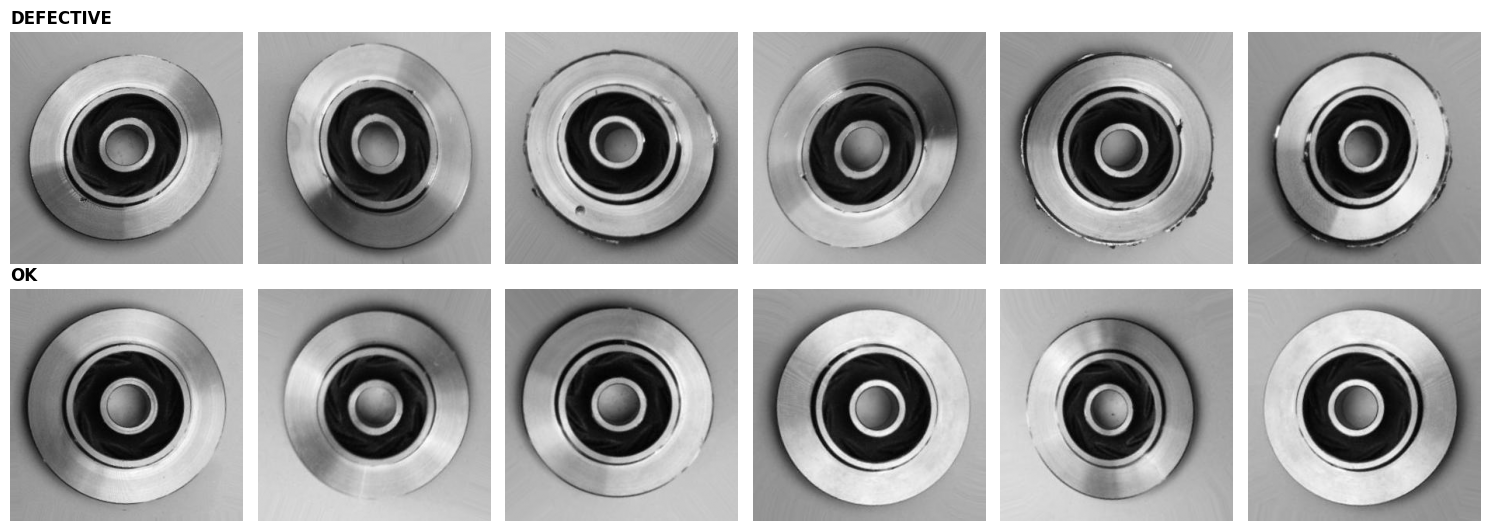

Image size: (300, 300) (colour channels are identical -> grayscale)


In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for row, lbl in enumerate([1, 0]):
    for ax, p in zip(axes[row], all_paths[all_y == lbl][:6]):
        ax.imshow(Image.open(p).convert("L"), cmap="gray"); ax.axis("off")
    axes[row, 0].set_title("DEFECTIVE" if lbl else "OK", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
print("Image size:", Image.open(all_paths[0]).size, "(colour channels are identical -> grayscale)")

**Why a CNN suits this task:** defects (blow holes, pinholes, burrs, broken edges) are **small and local** and can appear **anywhere** on the part. A 3×3 filter
is **shared across the whole image**, so the same weights detect a pinhole wherever it is — with a tiny fraction of the parameters a dense layer on 16,384 pixels would need.

## Step B2 — Data audit before splitting: labels and copies of the same casting
### Labels

filename prefix             cast_def  cast_ok  new__
author folder class folder                          
test          def_front          416        0     37
              ok_front             0      262      0
train         def_front         3758        0      0
              ok_front             0     2875      0


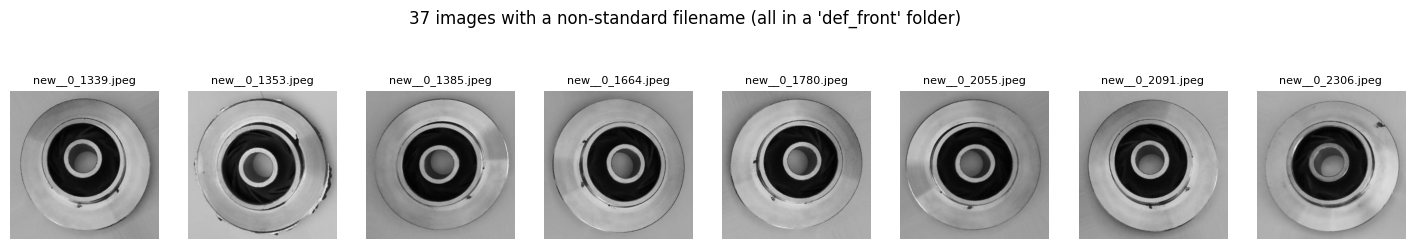

In [ ]:
def prefix(p):
    n = os.path.basename(p)
    return "cast_def" if n.startswith("cast_def") else "cast_ok" if n.startswith("cast_ok") else n.split("_")[0] + "__"
print(pd.crosstab([author_split, np.where(all_y == 1, "def_front", "ok_front")], [prefix(p) for p in all_paths],
                  rownames=["author folder", "class folder"], colnames=["filename prefix"]))
odd = [p for p in all_paths if prefix(p) not in ("cast_def", "cast_ok")]
fig, axes = plt.subplots(1, 8, figsize=(18, 2.8))
for ax, p in zip(axes, odd[:8]):
    ax.imshow(Image.open(p).convert("L"), cmap="gray"); ax.set_title(os.path.basename(p), fontsize=8); ax.axis("off")
plt.suptitle(f"{len(odd)} images with a non-standard filename (all in a 'def_front' folder)", y=1.05); plt.show()

No file sits in the wrong folder: every `cast_def…` file is in `def_front` and every `cast_ok…` file in `ok_front`. The only exceptions are 37 `new__…` files in the author's
test `def_front` folder; their names carry no label, several show visible defects, so the folder label is kept — but those 37 labels rest on the folder alone
(documented caveat).

### Copies of the same casting
The author augmented photographs (rotation, mirroring, lighting) **before** splitting them, so one physical casting can appear several times. To find these copies:
- each image is reduced to a 256-bit **difference hash** (16×16 grid of "is this pixel brighter than its right neighbour?");
- every image is hashed in **48 versions** (24 rotations every 15° × with/without mirror) and compared with every other image; the **Hamming distance** (number of
  differing bits) to the closest version is kept.

**Calibrating the threshold.** All impellers look alike, so a distance only means something against a baseline. A defective and an OK image **cannot** show the same
physical casting, so distances between **opposite-label** images show how close two *different* castings can look.

all-vs-all comparison of 7348 images: 127s


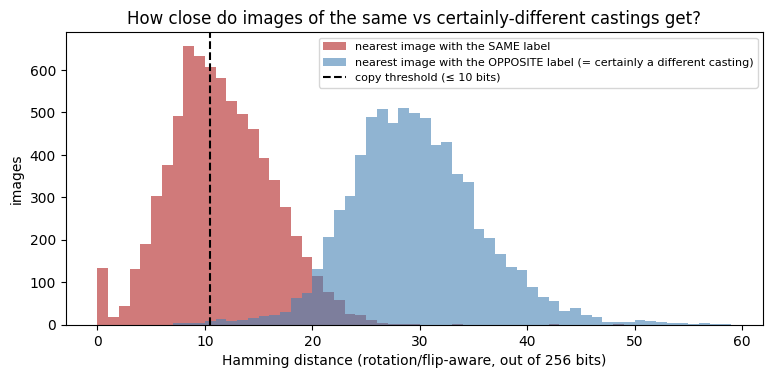

Opposite-label pairs within 10 bits: 21 images of 7348 (1st percentile of opposite-label distance: 15 bits)
Author's split: 333 of 715 author-test images (47%) have a copy (≤ 10 bits) in the author's training folder; 64 are byte-identical files.


In [ ]:
def dhash_bits(img, n=16):
    a = np.asarray(img.resize((n + 1, n), Image.BILINEAR), dtype=np.float32)
    return (a[:, 1:] > a[:, :-1]).ravel().astype(np.float32)

def small(p): return Image.open(p).convert("L").resize((64, 64), Image.BILINEAR)

def variants(img):                                         # 24 rotations x {original, mirrored}
    bg = int(np.median(np.asarray(img)[:4]))               # fill rotated corners with background grey
    out = []
    for b in (img, img.transpose(Image.FLIP_LEFT_RIGHT)):
        out += [dhash_bits(b.rotate(a, resample=Image.BILINEAR, fillcolor=bg)) for a in range(0, 360, 15)]
    return np.array(out)

def distances_to(query_paths, H_ref, chunk=60):
    # min Hamming distance (over the 48 versions of each query image) to every reference image
    out = []
    for s in range(0, len(query_paths), chunk):
        V = np.stack([variants(small(p)) for p in query_paths[s:s + chunk]]); A = V.reshape(-1, 256)
        out.append((256 - (A @ H_ref.T + (1 - A) @ (1 - H_ref).T)).reshape(len(V), 48, -1).min(1).astype(np.uint8))
    return np.concatenate(out)

t0 = time.time()
H_all = np.array([dhash_bits(small(p)) for p in all_paths])
D = distances_to(all_paths, H_all)
np.fill_diagonal(D, 255); D = np.minimum(D, D.T)                          # symmetric, ignore self-matches
print(f"all-vs-all comparison of {len(all_paths)} images: {time.time() - t0:.0f}s")

same_lab = all_y[:, None] == all_y[None, :]
nn_same = np.where(same_lab, D, 255).min(1); nn_opp = np.where(~same_lab, D, 255).min(1)
DUP_T = 10
plt.figure(figsize=(9, 3.8)); bins = np.arange(0, 60)
plt.hist(nn_same, bins, alpha=0.6, color="firebrick", label="nearest image with the SAME label")
plt.hist(nn_opp, bins, alpha=0.6, color="steelblue", label="nearest image with the OPPOSITE label (= certainly a different casting)")
plt.axvline(DUP_T + 0.5, color="black", ls="--", label=f"copy threshold (≤ {DUP_T} bits)")
plt.xlabel("Hamming distance (rotation/flip-aware, out of 256 bits)"); plt.ylabel("images"); plt.legend(fontsize=8)
plt.title("How close do images of the same vs certainly-different castings get?"); plt.show()

md5 = np.array([hashlib.md5(open(p, "rb").read()).hexdigest() for p in all_paths])
tr_a, te_a = author_split == "train", author_split == "test"
print(f"Opposite-label pairs within {DUP_T} bits: {int((nn_opp <= DUP_T).sum())} images of {len(all_paths)} "
      f"(1st percentile of opposite-label distance: {np.percentile(nn_opp, 1):.0f} bits)")
print(f"Author's split: {int((D[np.ix_(te_a, tr_a)].min(1) <= DUP_T).sum())} of {te_a.sum()} author-test images "
      f"({(D[np.ix_(te_a, tr_a)].min(1) <= DUP_T).mean():.0%}) have a copy (≤ {DUP_T} bits) in the author's training folder; "
      f"{int(np.isin(md5[te_a], md5[tr_a]).sum())} are byte-identical files.")

**Finding (our run).** Images of certainly-different castings (opposite labels) are rarely close: the 1st percentile of their distance is 15 bits, and only 21 of 7,348 images
have an opposite-label neighbour within 10 bits. Many same-label pairs sit at 0–10 bits, and the earlier inspection of such pairs showed the same casting rotated, mirrored or
relit. A threshold of **≤ 10 bits** therefore catches copies with very few false matches.
The author's own split is badly affected: **333 of the 715 author-test images (47%) have a copy in the author's training folder, and 64 are byte-identical files.**
**That is why we do not use the author's split.**

## Step B3 — Group-aware train / validation / test split (made before any training)
1. **Group:** link every pair of images within 10 bits and take connected components (union–find): each group = one casting and all its copies. Chaining makes some
   groups large; that is deliberate — it is conservative (it can only *over*-group, never leak).
2. **Split by group, stratified by class:** `StratifiedGroupKFold` with 20 folds; 14 folds → training (70%), 3 → validation (15%), 3 → test (~15%). No group is split
   across sets, and each set keeps the overall defective share.
3. **Verify:** no pair of images in different sets is within the copy threshold.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
parent = np.arange(len(all_paths))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for i, j in zip(*np.where(np.triu(D <= DUP_T, 1))):
    a, b = find(i), find(j)
    if a != b: parent[a] = b
groups = np.array([find(i) for i in range(len(all_paths))])
g_ids, g_sizes = np.unique(groups, return_counts=True)
mixed = sum(len(set(all_y[groups == g])) > 1 for g in g_ids[g_sizes > 1])
print(f"{len(g_ids)} groups | {int((g_sizes == 1).sum())} single images | largest group {g_sizes.max()} images | "
      f"{mixed} groups contain both labels (kept together: conservative)")

sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=RANDOM_STATE)
fold = np.empty(len(all_paths), int)
for k, (_, idx_k) in enumerate(sgkf.split(all_paths, all_y, groups)):
    fold[idx_k] = k
role = np.where(fold < 14, "train", np.where(fold < 17, "val", "test"))

split_table = pd.DataFrame({r: {"images": int((role == r).sum()), "groups": len(np.unique(groups[role == r])),
                                "defective": int(all_y[role == r].sum()), "OK": int((all_y[role == r] == 0).sum()),
                                "defective share": all_y[role == r].mean()} for r in ["train", "val", "test"]}).T
print(split_table.round(3))
for r1, r2 in [("train", "val"), ("train", "test"), ("val", "test")]:
    d = D[np.ix_(role == r1, role == r2)]
    assert not set(groups[role == r1]) & set(groups[role == r2])
    assert not np.isin(md5[role == r2], md5[role == r1]).any()
    print(f"{r1:5s} vs {r2:4s}: shared groups 0 | byte-identical files 0 | closest cross-split pair {int(d.min())} bits (> {DUP_T}: no copies across sets)")

4384 groups | 3753 single images | largest group 290 images | 6 groups contain both labels (kept together: conservative)
       images  groups  defective      OK  defective share
train  4868.0  3010.0     2881.0  1987.0            0.592
val     972.0   603.0      569.0   403.0            0.585
test   1508.0   771.0      761.0   747.0            0.505
train vs val : shared groups 0 | byte-identical files 0 | closest cross-split pair 11 bits (> 10: no copies across sets)
train vs test: shared groups 0 | byte-identical files 0 | closest cross-split pair 11 bits (> 10: no copies across sets)
val   vs test: shared groups 0 | byte-identical files 0 | closest cross-split pair 11 bits (> 10: no copies across sets)


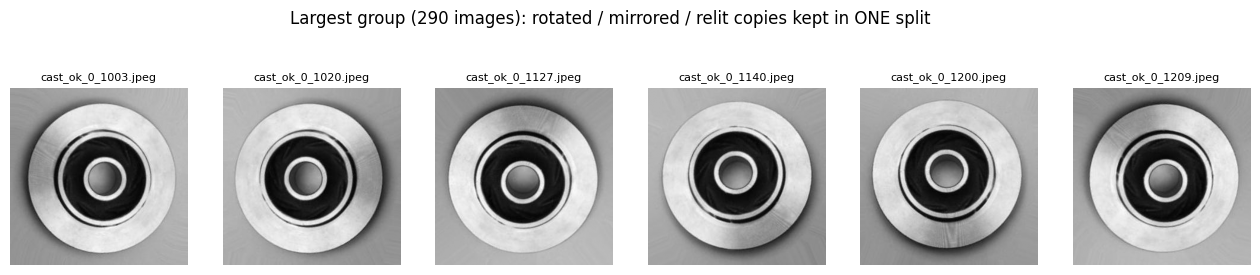

In [ ]:
# What one group looks like: the largest group, 6 of its images
g_big = g_ids[np.argmax(g_sizes)]
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, p in zip(axes, all_paths[groups == g_big][:6]):
    ax.imshow(Image.open(p).convert("L"), cmap="gray"); ax.axis("off"); ax.set_title(os.path.basename(p), fontsize=8)
plt.suptitle(f"Largest group ({g_sizes.max()} images): rotated / mirrored / relit copies kept in ONE split", y=1.05); plt.show()

**About the groups.** Most groups are small, but chaining joins many very similar-looking **OK** castings into a few large groups (largest: 290 images, shown above). These are
not all literal copies of one part. This over-grouping is the price of a conservative threshold: it can only make the test *harder*, never leak. Its side effect is
that large single-label groups cannot be divided, so the validation set ended up less defect-heavy (49%) than training (58.5%) and test (62%). Metrics are reported per
class (and with MCC) for that reason.

**Limitation (stated honestly).** Without real casting IDs, leakage can be *reduced* but not *ruled out*: the hash may miss copies that were transformed in ways it does not
model (e.g. strong crops or zoom), and two different castings can look alike. The grouped split removes every copy we can detect; the second export (Step B12), which
shares almost no copies with these images, provides an additional check on generalisation.

## Step B4 — Input pipeline
- Grayscale, 300×300 → **128×128** (keeps small defects visible, ~5.5× less computation); pixels scaled to 0–1 (as in Lesson 5).
- Built from the file lists of Step B3; decoded images are **cached** in memory after the first epoch (the main speed-up).

In [ ]:
IMG_SIZE, BATCH = (128, 128), 64
AUTOTUNE = tf.data.AUTOTUNE

def load_img(path, label):
    img = tf.image.resize(tf.io.decode_jpeg(tf.io.read_file(path), channels=1), IMG_SIZE) / 255.0
    return img, tf.reshape(tf.cast(label, tf.float32), [1])

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), labels)).map(load_img, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(paths), seed=RANDOM_STATE, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_paths, val_paths, test_paths = all_paths[role == "train"], all_paths[role == "val"], all_paths[role == "test"]
yb_train, yb_val, yb_test = all_y[role == "train"], all_y[role == "val"], all_y[role == "test"]
train_ds, val_ds, test_ds = make_ds(train_paths, yb_train, True), make_ds(val_paths, yb_val), make_ds(test_paths, yb_test)
N_TRAIN_IMG = len(train_paths)
labels_of = lambda ds: np.concatenate([lbl.numpy() for _, lbl in ds]).ravel().astype(int)
assert np.array_equal(labels_of(test_ds), yb_test) and np.array_equal(labels_of(val_ds), yb_val)
print(f"train {N_TRAIN_IMG} ({yb_train.mean():.1%} defective) | val {len(yb_val)} ({yb_val.mean():.1%}) | test {len(yb_test)} ({yb_test.mean():.1%})")

train 4868 (59.2% defective) | val 972 (58.5%) | test 1508 (50.5%)


## Step B5 — V1: the Lesson 5 baseline network

| Layer | Settings |
|---|---|
| Input | 128 × 128 × 1 |
| Conv2D | 32 filters, 3 × 3, `padding="same"`, ReLU |
| MaxPooling2D | 2 × 2 |
| Conv2D | 64 filters, 3 × 3, `padding="valid"`, ReLU |
| MaxPooling2D | 2 × 2 |
| Flatten | |
| Dense | **1 unit, sigmoid** (binary task, instead of Lesson 5's 10-unit softmax) |

**Loss: binary cross-entropy.** With one sigmoid output *p*: L = −[y·log p + (1−y)·log(1−p)]. It is the negative log-likelihood of a Bernoulli model, so it matches a
probability output, and its gradient with respect to the pre-sigmoid value is simply (p − y), so it does not stall the way squared error on a sigmoid can.
A 2-unit softmax with categorical cross-entropy is mathematically equivalent but needs twice the output weights. The output is written as `Dense(1)` (the *logit*)
followed by a sigmoid so the logit can be used for Grad-CAM in Step B10.

**Training set-up (all CNNs):** Adam (1e-3), batch 64, at most **20 epochs**, **early stopping** on validation loss (patience 5, best weights restored) and
**ReduceLROnPlateau**.

Model: "V1_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 62, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61504)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logit (Dense)                   │ (None, 1)              │        61,505 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Activation)             │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,321 (313.75 KB)

 Trainable params: 80,321 (313.75 KB)

 Non-trainable params: 0 (0.00 B)

conv1  formula =     320   Keras =     320
conv2  formula =  18,496   Keras =  18,496
logit  formula =  61,505   Keras =  61,505
Flatten size: 128→pool→64 ; 64−2 (valid conv) = 62 → pool → 31 ;  31 × 31 × 64 = 61,504
Epoch 1/20
77/77 - 17s - 224ms/step - accuracy: 0.6341 - loss: 0.6176 - pr_auc: 0.7575 - val_accuracy: 0.7860 - val_loss: 0.4509 - val_pr_auc: 0.9307 - learning_rate: 0.0010
Epoch 2/20
77/77 - 2s - 29ms/step - accuracy: 0.8398 - loss: 0.3688 - pr_auc: 0.9455 - val_accuracy: 0.7695 - val_loss: 0.4345 - val_pr_auc: 0.9730 - learning_rate: 0.0010
Epoch 3/20
77/77 - 2s - 29ms/step - accuracy: 0.8804 - loss: 0.2890 - pr_auc: 0.9682 - val_accuracy: 0.8796 - val_loss: 0.2905 - val_pr_auc: 0.9778 - learning_rate: 0.0010
Epoch 4/20
77/77 - 2s - 28ms/step - accuracy: 0.9182 - loss: 0.2240 - pr_auc: 0.9815 - val_accuracy: 0.7449 - val_loss: 0.3788 - val_pr_auc: 0.9827 - learning_rate: 0.0010
Epoch 5/20
77/77 - 2s - 29ms/step - accuracy: 0.9345 - loss: 0.1817 - pr_auc: 0.9882 - val_ac

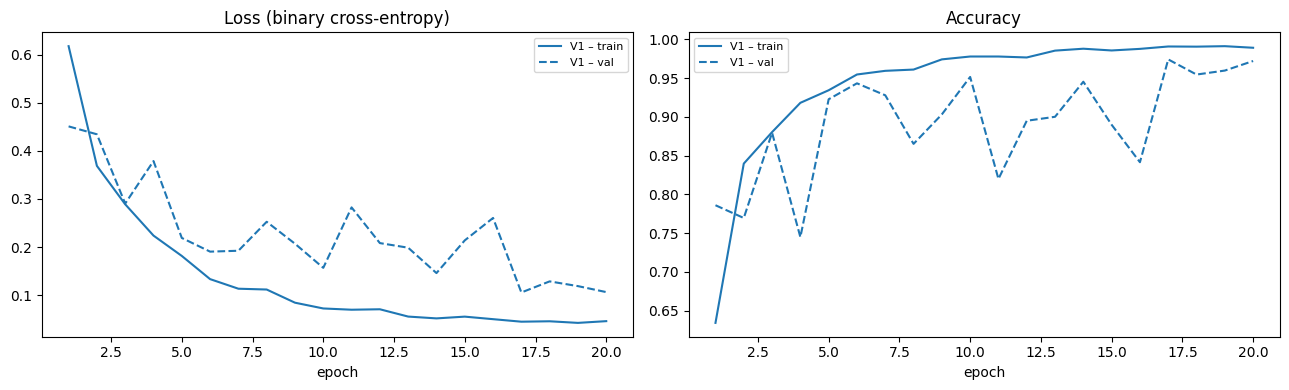

In [ ]:
def build_v1():
    return keras.Sequential([
        layers.Input(shape=(*IMG_SIZE, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"),
        layers.MaxPooling2D(2, name="pool1"),
        layers.Conv2D(64, 3, padding="valid", activation="relu", name="conv2"),
        layers.MaxPooling2D(2, name="pool2"),
        layers.Flatten(name="flatten"),
        layers.Dense(1, name="logit"), layers.Activation("sigmoid", name="output"),
    ], name="V1_baseline")

v1 = build_v1(); v1.summary()
flat = v1.get_layer("flatten").output.shape[-1]
for name, by_hand in {"conv1": conv_params(3, 1, 32), "conv2": conv_params(3, 32, 64), "logit": dense_params(flat, 1)}.items():
    print(f"{name:6s} formula = {by_hand:7,d}   Keras = {v1.get_layer(name).count_params():7,d}")
print(f"Flatten size: 128→pool→64 ; 64−2 (valid conv) = 62 → pool → 31 ;  31 × 31 × 64 = {flat:,d}")

EPOCHS_CNN = 20
def train_cnn(build_fn, data=None, epochs=EPOCHS_CNN, verbose=2):
    keras.utils.set_random_seed(RANDOM_STATE)
    model = build_fn()
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(curve="PR", name="pr_auc")])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)]
    t0 = time.time()
    h = model.fit(data if data is not None else train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs, verbose=verbose)
    return model, h.history, time.time() - t0

cnn_runs = {"V1 baseline": train_cnn(build_v1)}
plot_curves({"V1": cnn_runs["V1 baseline"][1]}, metrics=("loss", "accuracy"), titles=("Loss (binary cross-entropy)", "Accuracy"))

The **Flatten → Dense** layer holds most of the parameters (≈ 77%). That is where the network can memorise individual images.

## Step B6 — Look inside the network

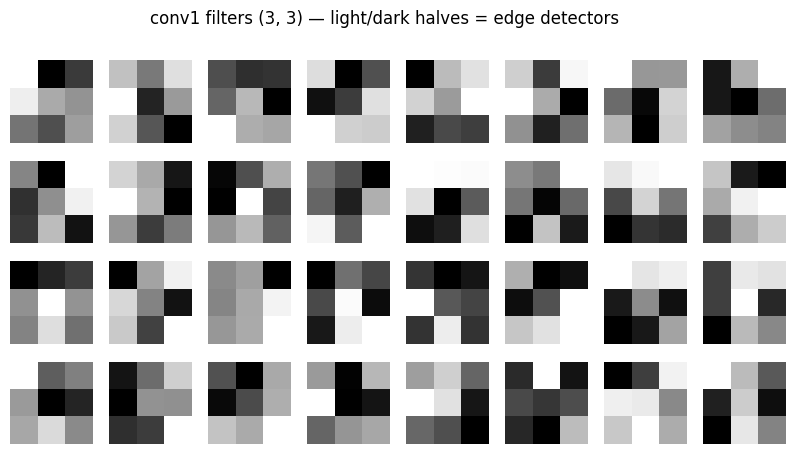

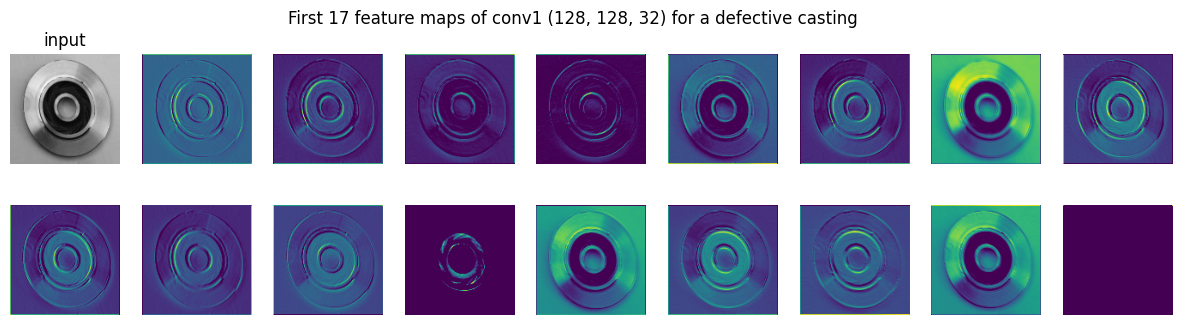

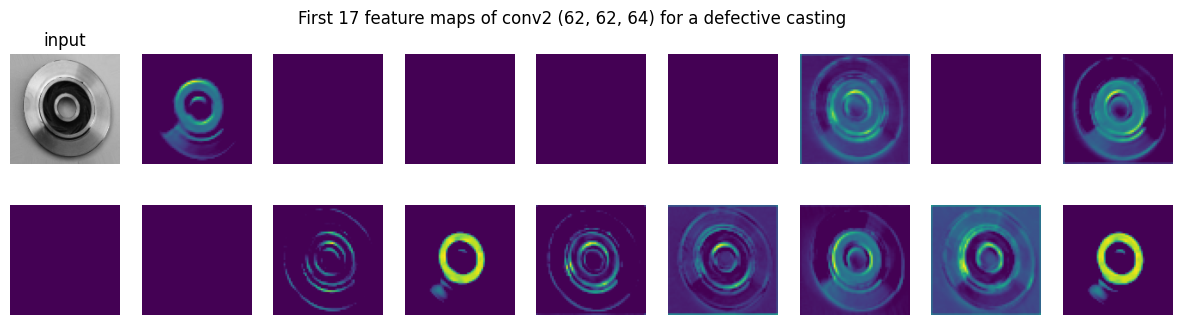

In [ ]:
cnn_v1 = cnn_runs["V1 baseline"][0]
w, b = cnn_v1.get_layer("conv1").get_weights()
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(w[:, :, 0, i], cmap="gray", interpolation="nearest"); ax.axis("off")
plt.suptitle(f"conv1 filters {w.shape[:2]} — light/dark halves = edge detectors"); plt.show()

X_test_img = np.concatenate([x.numpy() for x, _ in test_ds])
X_val_img = np.concatenate([x.numpy() for x, _ in val_ds])
i_def = int(np.where(yb_test == 1)[0][0])
probe = keras.Model(inputs=cnn_v1.inputs, outputs=[cnn_v1.get_layer("conv1").output, cnn_v1.get_layer("conv2").output])
fmap1, fmap2 = probe.predict(X_test_img[i_def:i_def + 1], verbose=0)
for name, fmap in [("conv1", fmap1), ("conv2", fmap2)]:
    fig, axes = plt.subplots(2, 9, figsize=(15, 3.6))
    axes[0, 0].imshow(X_test_img[i_def, ..., 0], cmap="gray"); axes[0, 0].set_title("input")
    for k, ax in enumerate(axes.flat[1:]):
        ax.imshow(fmap[0, :, :, k], cmap="viridis")
    for ax in axes.flat: ax.axis("off")
    plt.suptitle(f"First 17 feature maps of {name} {fmap.shape[1:]} for a defective casting"); plt.show()

`conv1` maps still look like the part (edges, rim, holes highlighted). `conv2` maps are smaller (after pooling and a *valid* convolution) and more abstract: each unit
sees a larger **receptive field** (8 × 8 input pixels after two 3×3 convolutions and a pooling step), so it responds to larger shapes.

## Step B7 — V2: data augmentation + dropout
- **Augmentation:** random **flips** and **rotations** (±18°) — physically plausible, since the impeller can lie rotated or mirrored on the conveyor. Switched off
  automatically at test time.
- **Dropout (0.3)** before the dense layer stops it relying on any single flattened feature. Neither adds parameters.

*Iteration note:* an earlier attempt (on the author's original split) with stronger settings (±36° rotation, ±5% shifts, dropout 0.5, no learning-rate schedule) learned too slowly (training accuracy
≈ 0.88 when early stopping fired at epoch 11); the milder settings were adopted after comparing validation results.

In [ ]:
def augmentation():
    return [layers.RandomFlip("horizontal_and_vertical", seed=RANDOM_STATE),
            layers.RandomRotation(0.05, fill_mode="reflect", seed=RANDOM_STATE)]       # 0.05 of a full turn = ±18°

def build_v2():
    return keras.Sequential([
        layers.Input(shape=(*IMG_SIZE, 1)), *augmentation(),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"), layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, padding="valid", activation="relu", name="conv2"), layers.MaxPooling2D(2),
        layers.Flatten(), layers.Dropout(0.3),
        layers.Dense(1, name="logit"), layers.Activation("sigmoid", name="output"),
    ], name="V2_augment_dropout")

cnn_runs["V2 augment + dropout"] = train_cnn(build_v2)

Epoch 1/20
77/77 - 7s - 90ms/step - accuracy: 0.6976 - loss: 0.5629 - pr_auc: 0.8259 - val_accuracy: 0.8179 - val_loss: 0.4229 - val_pr_auc: 0.9347 - learning_rate: 0.0010
Epoch 2/20
77/77 - 2s - 27ms/step - accuracy: 0.8184 - loss: 0.3944 - pr_auc: 0.9318 - val_accuracy: 0.9012 - val_loss: 0.3005 - val_pr_auc: 0.9726 - learning_rate: 0.0010
Epoch 3/20
77/77 - 2s - 28ms/step - accuracy: 0.8809 - loss: 0.2907 - pr_auc: 0.9693 - val_accuracy: 0.7932 - val_loss: 0.4387 - val_pr_auc: 0.9788 - learning_rate: 0.0010
Epoch 4/20
77/77 - 2s - 27ms/step - accuracy: 0.9108 - loss: 0.2289 - pr_auc: 0.9809 - val_accuracy: 0.9115 - val_loss: 0.2232 - val_pr_auc: 0.9852 - learning_rate: 0.0010
Epoch 5/20
77/77 - 2s - 27ms/step - accuracy: 0.9376 - loss: 0.1753 - pr_auc: 0.9882 - val_accuracy: 0.8477 - val_loss: 0.3219 - val_pr_auc: 0.9872 - learning_rate: 0.0010
Epoch 6/20
77/77 - 2s - 27ms/step - accuracy: 0.9408 - loss: 0.1620 - pr_auc: 0.9895 - val_accuracy: 0.9393 - val_loss: 0.1748 - val_pr_auc:

## Step B8 — V3: global average pooling + one more conv block
Replacing `Flatten` with **GlobalAveragePooling2D** removes the big dense weight matrix (each feature map is averaged to one number). It noted that GAP alone
leaves few features to classify with and suggested **another conv block** — so V3 adds a third block (128 filters) and a small dense layer; the extra block also enlarges
the receptive field. Augmentation and dropout are kept from V2.

V3 parameters: 100,993  vs  V1/V2: 80,321
conv3 by formula = 73,856 | GAP outputs 128 numbers instead of 61,504 -> head = 8,321 weights instead of 61,505
Epoch 1/20
77/77 - 5s - 65ms/step - accuracy: 0.5918 - loss: 0.6804 - pr_auc: 0.5713 - val_accuracy: 0.5854 - val_loss: 0.6774 - val_pr_auc: 0.7919 - learning_rate: 0.0010
Epoch 2/20
77/77 - 3s - 33ms/step - accuracy: 0.5918 - loss: 0.6760 - pr_auc: 0.6082 - val_accuracy: 0.5854 - val_loss: 0.6717 - val_pr_auc: 0.8385 - learning_rate: 0.0010
Epoch 3/20
77/77 - 3s - 33ms/step - accuracy: 0.5918 - loss: 0.6680 - pr_auc: 0.6573 - val_accuracy: 0.5854 - val_loss: 0.6627 - val_pr_auc: 0.7614 - learning_rate: 0.0010
Epoch 4/20
77/77 - 3s - 33ms/step - accuracy: 0.6372 - loss: 0.6440 - pr_auc: 0.7084 - val_accuracy: 0.5854 - val_loss: 0.7181 - val_pr_auc: 0.7783 - learning_rate: 0.0010
Epoch 5/20
77/77 - 3s - 33ms/step - accuracy: 0.7223 - loss: 0.5872 - pr_auc: 0.7659 - val_accuracy: 0.6584 - val_loss: 0.6042 - val_pr_auc: 0.8354 - learning

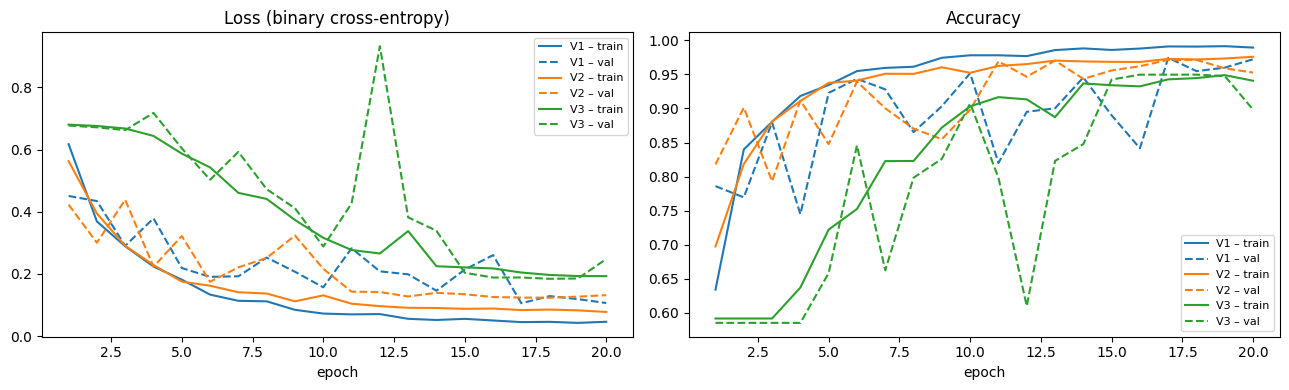

In [ ]:
def build_v3():
    return keras.Sequential([
        layers.Input(shape=(*IMG_SIZE, 1)), *augmentation(),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"), layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, padding="valid", activation="relu", name="conv2"), layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, padding="valid", activation="relu", name="conv3"), layers.MaxPooling2D(2),
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(64, activation="relu"), layers.Dropout(0.3),
        layers.Dense(1, name="logit"), layers.Activation("sigmoid", name="output"),
    ], name="V3_gap_deeper")

v3 = build_v3()
print(f"V3 parameters: {v3.count_params():,d}  vs  V1/V2: {v1.count_params():,d}")
print(f"conv3 by formula = {conv_params(3, 64, 128):,d} | GAP outputs {v3.get_layer('gap').output.shape[-1]} numbers instead of {flat:,d} "
      f"-> head = {dense_params(128, 64) + dense_params(64, 1):,d} weights instead of {dense_params(flat, 1):,d}")
cnn_runs["V3 GAP + 3rd conv block"] = train_cnn(build_v3)
plot_curves({k.split()[0]: v[1] for k, v in cnn_runs.items()}, metrics=("loss", "accuracy"), titles=("Loss (binary cross-entropy)", "Accuracy"))

**How to read the three sets of curves (capacity and over-/underfitting) — on the grouped split, validation now contains no copies of training castings**
- **V1 overfits.** Its training loss falls to ≈ 0.07, while its validation loss stalls around 0.25–0.30 and validation accuracy stays near 0.87–0.90. A persistent gap like this is
  the classic overfitting signature: the large Flatten→Dense layer memorises training castings. *On the author's leaky split this gap was invisible*,
  because validation images were copies of training images.
- **V2 closes most of the gap.** Augmentation and dropout bring validation loss down to ≈ 0.09 and validation accuracy to ≈ 0.97. Its training loss sits close to V1's even
  though it trains on transformed images. That is what regularisation should do when there *is* overfitting to remove.
- **V3 underfits.** Training loss is still ≈ 0.22 after 20 epochs and its validation curves swing widely. As Lesson 5 anticipated, the GAP head leaves few
  features to classify with and learns slowly. It needs more epochs or capacity, not more regularisation.
- **Noisy validation curves:** validation is grouped, so each epoch's validation set contains castings the network has never seen. Small shifts in the decision boundary move
  many images at once.

## Step B9 — Select on validation, then evaluate on the grouped test set once
**Pre-declared selection rule:** the version with the lowest validation loss; its decision threshold maximises F1 on validation. Both are fixed before the test set is used.

In [ ]:
rows = []
cnn_val_proba_all, cnn_thr_all = {}, {}
for name, (model, h, secs) in cnn_runs.items():
    vp = model.predict(val_ds, verbose=0).ravel(); b = int(np.argmin(h["val_loss"]))
    cnn_val_proba_all[name], cnn_thr_all[name] = vp, best_threshold(yb_val, vp)
    rows.append({"Version": name, "params": model.count_params(), "epochs run": len(h["loss"]), "best epoch": b + 1,
                 "train loss @best": h["loss"][b], "val loss @best": h["val_loss"][b],
                 "val PR-AUC": average_precision_score(yb_val, vp), "val F1 (own threshold)": f1_score(yb_val, vp >= cnn_thr_all[name]),
                 "val MCC": matthews_corrcoef(yb_val, vp >= cnn_thr_all[name]), "threshold": cnn_thr_all[name],
                 "train time (s)": secs, "s / epoch": secs / len(h["loss"])})
cnn_table = pd.DataFrame(rows)
best_cnn_name = cnn_table.sort_values(["val loss @best", "val PR-AUC"], ascending=[True, False]).iloc[0]["Version"]
cnn, cnn_hist, cnn_train_time = cnn_runs[best_cnn_name]
cnn_val_proba, cnn_thr = cnn_val_proba_all[best_cnn_name], cnn_thr_all[best_cnn_name]
print("Selected on validation loss (before looking at test):", best_cnn_name, f"| threshold {cnn_thr:.3f}")
cnn_table.round(4)

Selected on validation loss (before looking at test): V1 baseline | threshold 0.559


,Version,params,epochs run,best epoch,train loss @best,val loss @best,val PR-AUC,val F1 (own threshold),val MCC,threshold,train time (s),s / epoch
0,V1 baseline,80321,20,17,0.0450,0.1057,0.9978,0.9832,0.9599,0.5590,58.8754,2.9438
1,V2 augment + dropout,80321,20,18,0.0854,0.1236,0.9953,0.9798,0.9513,0.4077,47.3365,2.3668
2,V3 GAP + 3rd conv block,100993,20,18,0.1968,0.1844,0.9713,0.9688,0.9238,0.2553,53.0524,2.6526


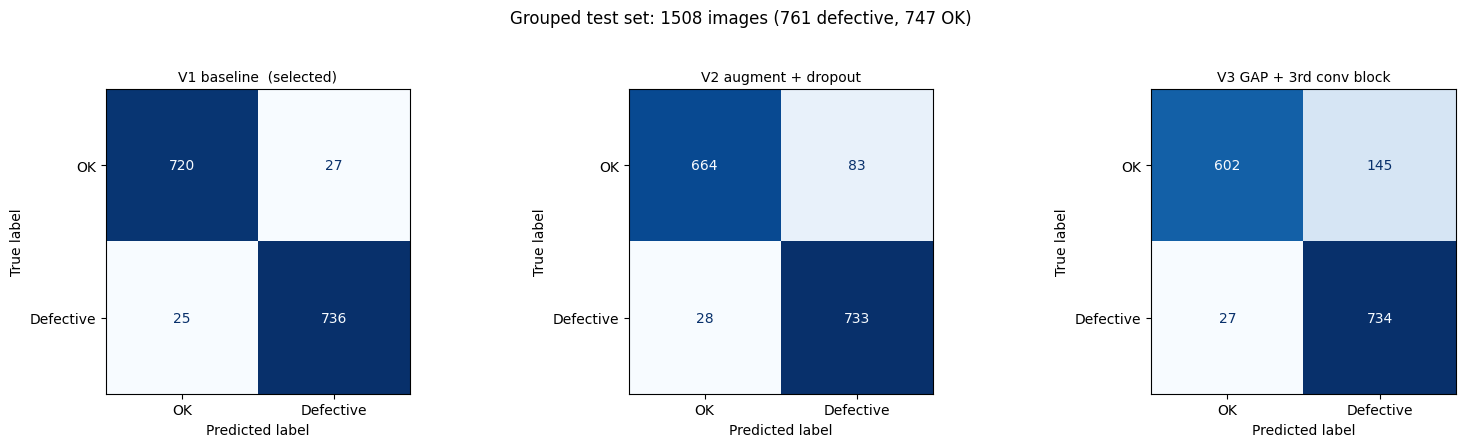

Model,V1 baseline,V2 augment + dropout,V3 GAP + 3rd conv block
Threshold,0.5590,0.4080,0.2550
Precision,0.9646,0.8983,0.8350
Recall,0.9671,0.9632,0.9645
F1,0.9659,0.9296,0.8951
PR-AUC,0.9942,0.9876,0.9658
ROC-AUC,0.9929,0.9847,0.9650
MCC,0.9310,0.8550,0.7812
Balanced acc,0.9655,0.9260,0.8852
Accuracy,0.9655,0.9264,0.8859
TP,736.0000,733.0000,734.0000


In [ ]:
rows, cnn_test_proba_all = [], {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, (name, (model, h, secs)) in zip(axes, cnn_runs.items()):
    t0 = time.time(); proba = model.predict(test_ds, verbose=0).ravel(); inf = (time.time() - t0) / len(yb_test)
    cnn_test_proba_all[name] = proba
    r = evaluate(yb_test, proba, cnn_thr_all[name], name)
    r.update({"params": model.count_params(), "train time (s)": secs, "inference (ms / image)": inf * 1000})
    rows.append(r)
    ConfusionMatrixDisplay(confusion_matrix(yb_test, (proba >= cnn_thr_all[name]).astype(int)), display_labels=["OK", "Defective"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}{'  (selected)' if name == best_cnn_name else ''}", fontsize=10)
plt.suptitle(f"Grouped test set: {len(yb_test)} images ({int(yb_test.sum())} defective, {int((yb_test == 0).sum())} OK)", y=1.03)
plt.tight_layout(); plt.show()
cnn_test_all = pd.DataFrame(rows).set_index("Model")
cnn_test_proba = cnn_test_proba_all[best_cnn_name]
cnn_test_all.T.round(4)

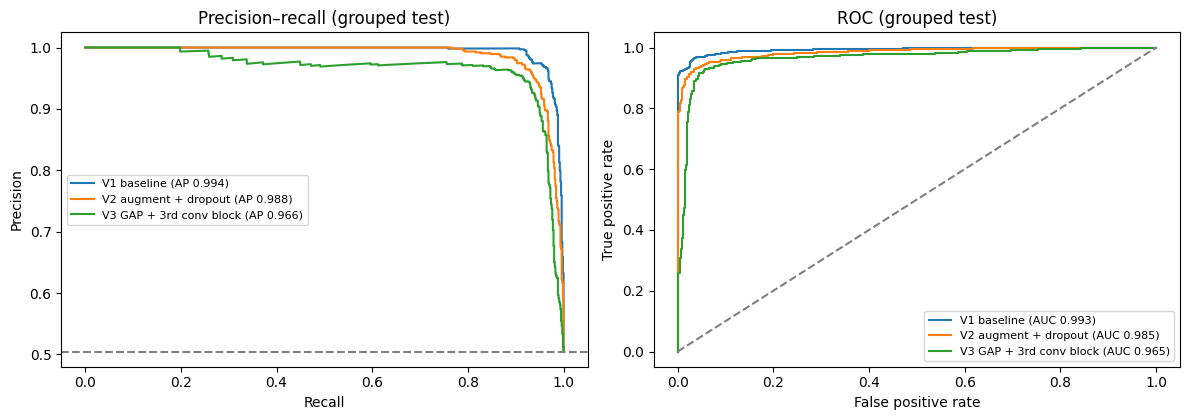

              precision    recall  f1-score   support

          OK     0.9664    0.9639    0.9651       747
   Defective     0.9646    0.9671    0.9659       761

    accuracy                         0.9655      1508
   macro avg     0.9655    0.9655    0.9655      1508
weighted avg     0.9655    0.9655    0.9655      1508

V1 baseline: 95% bootstrap CI  F1 [0.9567, 0.9753]   PR-AUC [0.9918, 0.9964]
52 of 1508 test images misclassified: 25 missed defects, 27 false rejects


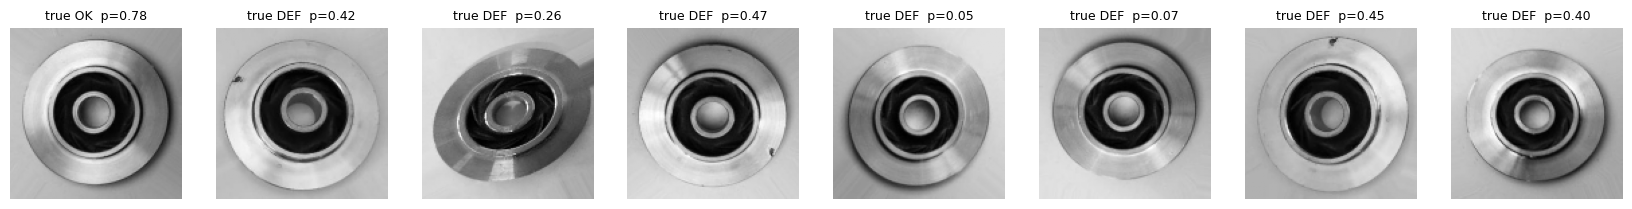

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for name, proba in cnn_test_proba_all.items():
    p, r, _ = precision_recall_curve(yb_test, proba); axes[0].plot(r, p, label=f"{name} (AP {average_precision_score(yb_test, proba):.3f})")
    fpr, tpr, _ = roc_curve(yb_test, proba); axes[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(yb_test, proba):.3f})")
axes[0].axhline(yb_test.mean(), ls="--", c="grey"); axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision–recall (grouped test)"); axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], "--", c="grey"); axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (grouped test)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
cnn_pred = (cnn_test_proba >= cnn_thr).astype(int)
print(classification_report(yb_test, cnn_pred, target_names=["OK", "Defective"], digits=4))
(f_lo, f_hi), (a_lo, a_hi) = bootstrap_ci(yb_test, cnn_test_proba, cnn_thr)
print(f"{best_cnn_name}: 95% bootstrap CI  F1 [{f_lo:.4f}, {f_hi:.4f}]   PR-AUC [{a_lo:.4f}, {a_hi:.4f}]")
wrong = np.where(cnn_pred != yb_test)[0]
print(f"{len(wrong)} of {len(yb_test)} test images misclassified: {int((cnn_pred[wrong] == 0).sum())} missed defects, {int((cnn_pred[wrong] == 1).sum())} false rejects")
if len(wrong):
    n = min(len(wrong), 8)
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 3), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n]):
        ax.imshow(X_test_img[i, ..., 0], cmap="gray"); ax.axis("off")
        ax.set_title(f"true {'DEF' if yb_test[i] else 'OK'}  p={cnn_test_proba[i]:.2f}", fontsize=9)
    plt.show()

**Reading the grouped-test results (our run).** The selected **V2** reaches F1 **0.968** and MCC **0.922** on 1,020 unseen castings (630 defective / 390 OK). It missed **35**
defects (recall 0.944) and rejected **4** good parts (bootstrap 95% CI for F1: 0.958–0.978). V1 dropped to F1 0.914 with 91 missed defects, and V3 reached 0.932.
These are **lower** than the ~99.9% the author's split gave, and that difference is the size of the leakage effect: the old split partly measured memory of copies.
The ranking V2 > V3 > V1 matches validation, so the selection rule chose well. The errors are almost all **missed defects**, the costly direction, which is why
Part C revisits the threshold.

## Step B10 — Where does the CNN look? Grad-CAM, and how much data it needs
**Grad-CAM** (Selvaraju et al., 2017) weights the last convolutional feature maps by the gradient of the prediction to show *where* the evidence came from. We use the
**logit** (pre-sigmoid) because when the model is ~100% confident the sigmoid is flat and its gradient vanishes. Each map explains the **predicted** class.

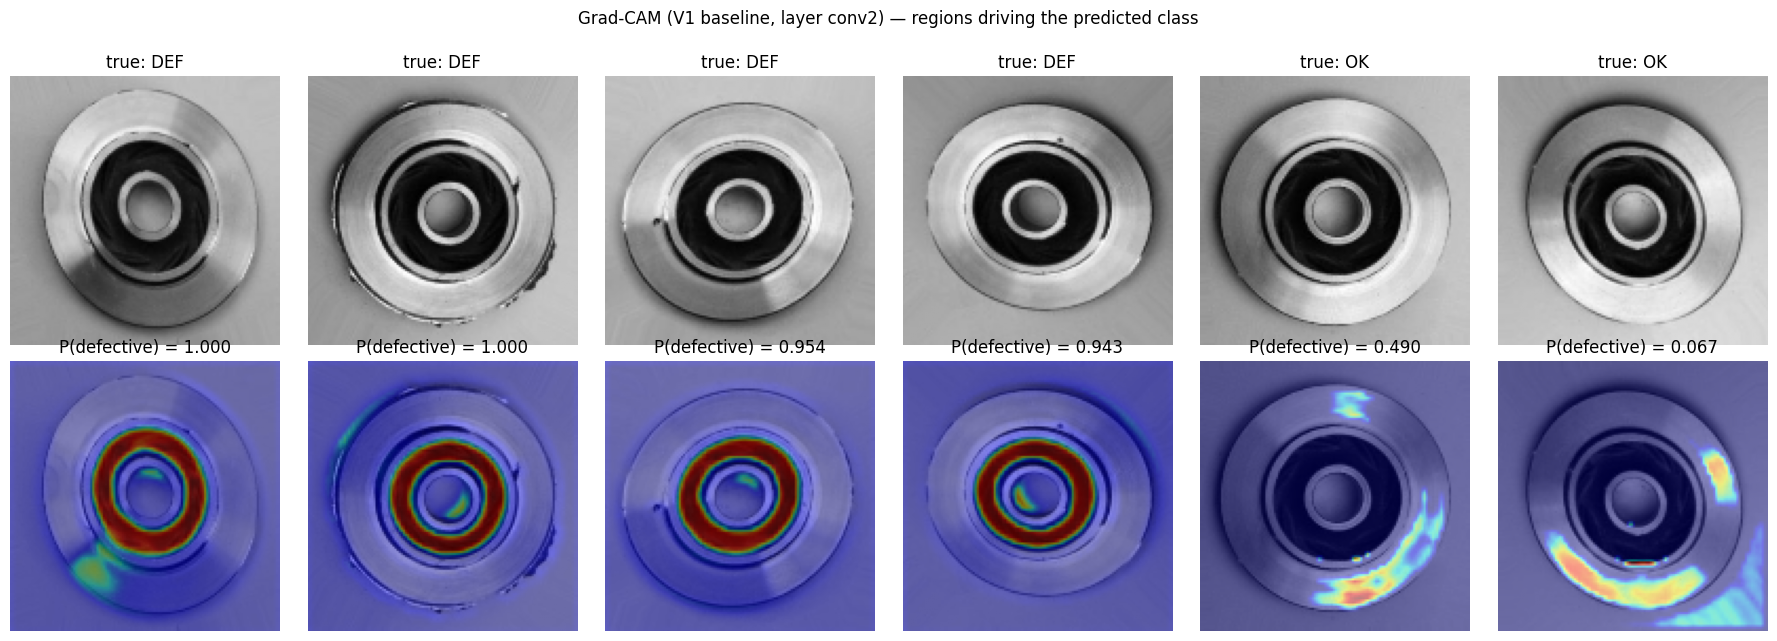

In [ ]:
last_conv = [l for l in cnn.layers if isinstance(l, layers.Conv2D)][-1].name
grad_model = keras.Model(cnn.inputs, [cnn.get_layer(last_conv).output, cnn.get_layer("logit").output])

def grad_cam(image):
    with tf.GradientTape() as tape:
        conv_out, logit = grad_model(image, training=False)
        sign = 1.0 if float(tf.sigmoid(logit[0, 0])) >= cnn_thr else -1.0      # + explains 'defective', − explains 'OK'
        score = sign * logit[:, 0]
    grads = tape.gradient(score, conv_out)
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * tf.reduce_mean(grads, axis=(0, 1, 2)), axis=-1)).numpy()
    return tf.image.resize((cam / (cam.max() + 1e-8))[..., None], IMG_SIZE).numpy()[..., 0]

show = list(np.where(yb_test == 1)[0][:4]) + list(np.where(yb_test == 0)[0][:2])
fig, axes = plt.subplots(2, len(show), figsize=(3 * len(show), 6.3))
for j, i in enumerate(show):
    axes[0, j].imshow(X_test_img[i, ..., 0], cmap="gray"); axes[0, j].set_title(f"true: {'DEF' if yb_test[i] else 'OK'}")
    axes[1, j].imshow(X_test_img[i, ..., 0], cmap="gray"); axes[1, j].imshow(grad_cam(X_test_img[i:i + 1]), cmap="jet", alpha=0.45)
    axes[1, j].set_title(f"P(defective) = {cnn_test_proba[i]:.3f}")
for ax in axes.flat: ax.axis("off")
plt.suptitle(f"Grad-CAM ({best_cnn_name}, layer {last_conv}) — regions driving the predicted class", y=1.01); plt.tight_layout(); plt.show()

**Reading the maps.** For parts predicted defective, V2's evidence concentrates on the inner ring. In some images it also covers a **rim segment** — in the 3rd defective
example that segment matches a visible burr on the left edge. For OK parts the evidence is spread over the smooth outer surface. So the network does look at the part and partly at the
defects. It does not localise every defect precisely, though, so the heat-map can support an inspector but not replace one.

**Data requirements (evidence for Part C):** retrain the selected architecture on 10% and 30% of the training images (max 12 epochs) and score on the same validation set.

In [ ]:
BUILDERS = {"V1 baseline": build_v1, "V2 augment + dropout": build_v2, "V3 GAP + 3rd conv block": build_v3}
perm = np.random.default_rng(RANDOM_STATE).permutation(N_TRAIN_IMG)
rows = []
for frac in [0.1, 0.3]:
    k = int(round(frac * N_TRAIN_IMG))
    m, _, _ = train_cnn(BUILDERS[best_cnn_name], data=make_ds(train_paths[perm[:k]], yb_train[perm[:k]], True), epochs=12, verbose=0)
    rows.append({"fraction": frac, "training images": k, "CNN val PR-AUC": average_precision_score(yb_val, m.predict(val_ds, verbose=0).ravel())})
rows.append({"fraction": 1.0, "training images": N_TRAIN_IMG, "CNN val PR-AUC": average_precision_score(yb_val, cnn_val_proba)})
dataB = pd.DataFrame(rows)
dataB.round(4)

,fraction,training images,CNN val PR-AUC
0,0.1,487,0.9582
1,0.3,1460,0.9811
2,1.0,4868,0.9978


**Reading the data-requirements table.** With 10% or 30% of the training images and at most 12 epochs, V2 barely beats chance on validation (PR-AUC ≈ 0.60–0.63, against a
no-skill level of 0.49). With all images it reaches 0.997. Part of the gap comes from far fewer gradient steps, since the smaller runs see 3–10× fewer batches. The result
still shows that this CNN needs thousands of labelled images.

## Step B11 — Shortcut and robustness checks
1. **Background masking:** replace everything outside the circle containing the part with plain grey. If predictions barely change, the CNN is not using the background.
2. **Realistic imaging changes** a new camera or lighting set-up could cause: brightness ±20%, lower contrast, blur, sensor noise, a 45° rotation.

The checks are run on the **validation** set (that is what any deployment choice may use) and reported on the **test** set for completeness.

In [ ]:
from scipy import ndimage
H_, W_ = IMG_SIZE
yy, xx = np.mgrid[:H_, :W_]
outside = ((yy - H_ / 2) ** 2 + (xx - W_ / 2) ** 2) > (0.5 * W_) ** 2

def mask_background(X):
    Xm = X.copy()
    for i in range(len(Xm)):
        Xm[i, ..., 0][outside] = np.median(X[i, ..., 0][outside])
    return Xm

perturb = {
    "none": lambda X: X,
    "background masked": mask_background,
    "brightness −20%": lambda X: np.clip(X * 0.8, 0, 1),
    "brightness +20%": lambda X: np.clip(X * 1.2, 0, 1),
    "contrast −30%": lambda X: np.clip((X - X.mean(axis=(1, 2, 3), keepdims=True)) * 0.7 + X.mean(axis=(1, 2, 3), keepdims=True), 0, 1),
    "blur (σ = 1.5 px)": lambda X: ndimage.gaussian_filter(X, sigma=(0, 1.5, 1.5, 0)),
    "noise (σ = 0.05)": lambda X: np.clip(X + np.random.default_rng(RANDOM_STATE).normal(0, 0.05, X.shape), 0, 1),
    "rotation 45°": lambda X: ndimage.rotate(X, 45, axes=(1, 2), reshape=False, mode="reflect"),
}
robust = {}
for split_name, Xs_, ys_ in [("validation", X_val_img, yb_val), ("test", X_test_img, yb_test)]:
    rows = []
    for pname, fn in perturb.items():
        Xp = fn(Xs_).astype(np.float32); row = {"perturbation": pname}
        for name, (model, _, _) in cnn_runs.items():
            pred = model.predict(Xp, verbose=0, batch_size=128).ravel() >= cnn_thr_all[name]
            row[f"{name.split()[0]} F1"] = f1_score(ys_, pred); row[f"{name.split()[0]} recall"] = recall_score(ys_, pred)
            row[f"{name.split()[0]} MCC"] = matthews_corrcoef(ys_, pred)
        rows.append(row)
    robust[split_name] = pd.DataFrame(rows).set_index("perturbation")
print("VALIDATION set (used for any deployment decision):"); display(robust["validation"].round(3))
print("TEST set (reported only):"); display(robust["test"].round(3))

VALIDATION set (used for any deployment decision):


,V1 F1,V1 recall,V1 MCC,V2 F1,V2 recall,V2 MCC,V3 F1,V3 recall,V3 MCC
perturbation,,,,,,,,,
none,0.983,0.979,0.960,0.980,0.979,0.951,0.969,0.982,0.924
background masked,0.980,0.965,0.954,0.970,0.951,0.932,0.968,0.981,0.922
brightness −20%,0.739,1.000,0.038,0.764,1.000,0.282,0.746,1.000,0.154
brightness +20%,0.510,0.343,0.422,0.723,0.566,0.592,0.045,0.023,0.098
contrast −30%,0.925,0.981,0.813,0.970,0.953,0.929,0.738,1.000,0.000
blur (σ = 1.5 px),0.738,1.000,0.000,0.738,1.000,0.000,0.738,1.000,0.000
noise (σ = 0.05),0.930,0.974,0.826,0.838,0.996,0.571,0.222,0.125,0.230
rotation 45°,0.859,1.000,0.635,0.962,0.988,0.908,0.959,0.984,0.899


TEST set (reported only):


,V1 F1,V1 recall,V1 MCC,V2 F1,V2 recall,V2 MCC,V3 F1,V3 recall,V3 MCC
perturbation,,,,,,,,,
none,0.966,0.967,0.931,0.930,0.963,0.855,0.895,0.965,0.781
background masked,0.964,0.955,0.927,0.948,0.946,0.895,0.904,0.966,0.799
brightness −20%,0.672,1.000,0.058,0.685,1.000,0.181,0.676,0.999,0.102
brightness +20%,0.541,0.371,0.475,0.690,0.527,0.596,0.064,0.033,0.129
contrast −30%,0.822,0.980,0.619,0.904,0.943,0.800,0.671,1.000,0.000
blur (σ = 1.5 px),0.671,1.000,0.000,0.671,1.000,0.000,0.671,1.000,0.000
noise (σ = 0.05),0.893,0.958,0.777,0.786,0.992,0.534,0.240,0.137,0.270
rotation 45°,0.813,0.997,0.601,0.891,0.975,0.774,0.855,0.970,0.692


**Reading the robustness tables (decisions read from validation; the test table agrees)**
- **No background shortcut:** masking the background changes V2's validation F1 only from 0.977 to 0.973.
- **Brighter images (+20%) are dangerous:** V2's recall falls to ≈ 0.49, so about half of the defective castings would be passed. V1 behaves similarly, and V3 is worse (0.16).
- **Darker images (−20%) and blur:** recall stays ≈ 1.0 but MCC collapses (V2: 0.42 and 0.08), because the model flags nearly **every** part as defective. That direction is
  fail-safe but useless.
- **Noise and rotation:** a 45° rotation does not hurt V2 (0.977 → 0.977). Noise costs V2 a little (0.937), while V3 degrades badly (recall 0.71).
- **Conclusion:** V2 is the most robust of the three to geometry and noise, and **none** is robust to lighting, which training never varied. Lighting must be fixed and
  monitored at the inspection station, and brightness/contrast augmentation is the obvious next iteration.

## Step B12 — External check on the second export (`casting_512x512`)
This set is **not used for training, selection or thresholds** — every model uses its validation threshold. Three questions:
1. Does it overlap with the 7,348 images (copies of the same castings)?
2. How well does each version do on it — precision, recall, F1, MCC and confusion matrices?
3. *Why* might performance differ — class balance, size, framing, brightness, contrast, sharpness, compression?

21 of 1300 export images have a copy (≤ 10 bits) among the 7,348 images; 1279 are independent at this threshold (25s)


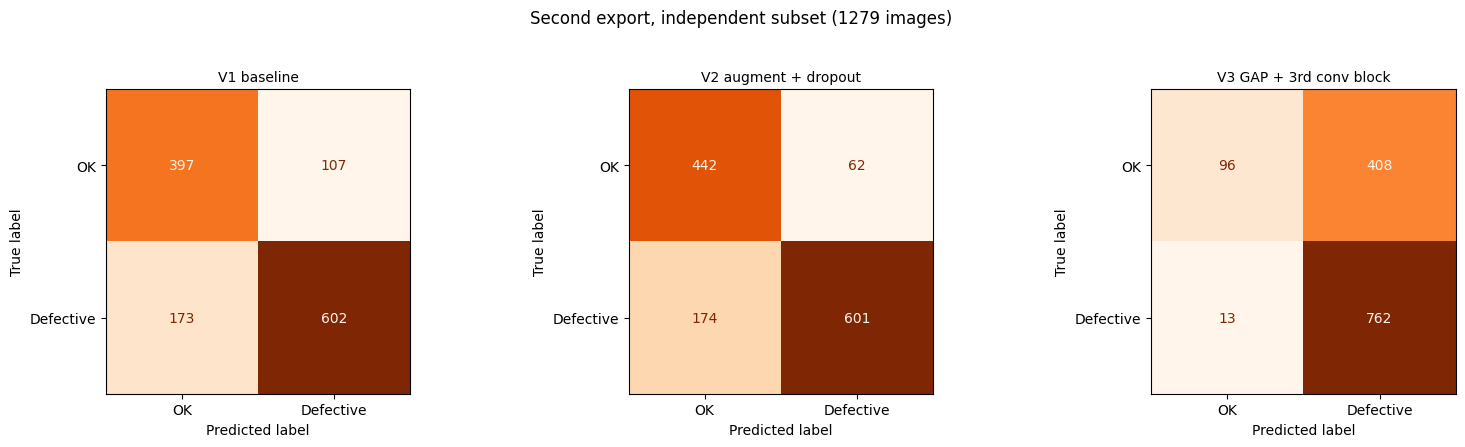

,version,subset,images,defective share,Precision,Recall,F1,PR-AUC,MCC,TP,FN,FP,TN
0,V1 baseline,all export images,1300,0.6008,0.8490,0.7772,0.8115,0.9098,0.5602,607,174,108,411
1,V1 baseline,independent subset,1279,0.6059,0.8491,0.7768,0.8113,0.9101,0.5549,602,173,107,397
2,V2 augment + dropout,all export images,1300,0.6008,0.9031,0.7759,0.8347,0.9319,0.6377,606,175,65,454
3,V2 augment + dropout,independent subset,1279,0.6059,0.9065,0.7755,0.8359,0.9329,0.6381,601,174,62,442
4,V3 GAP + 3rd conv block,all export images,1300,0.6008,0.6476,0.9834,0.7809,0.8252,0.3081,768,13,418,101
5,V3 GAP + 3rd conv block,independent subset,1279,0.6059,0.6513,0.9832,0.7835,0.8248,0.3040,762,13,408,96


In [ ]:
t0 = time.time()
d_ext = distances_to(ext_paths, H_all).min(1)
ext_indep = d_ext > DUP_T
print(f"{int((~ext_indep).sum())} of {len(ext_paths)} export images have a copy (≤ {DUP_T} bits) among the 7,348 images; "
      f"{int(ext_indep.sum())} are independent at this threshold ({time.time() - t0:.0f}s)")

ext_ds = make_ds(ext_paths, ext_y)
X_ext_img = np.concatenate([x.numpy() for x, _ in ext_ds])
rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, (name, (model, _, _)) in zip(axes, cnn_runs.items()):
    proba = model.predict(X_ext_img, verbose=0, batch_size=128).ravel()
    for sub, m in [("all export images", np.ones(len(ext_y), bool)), ("independent subset", ext_indep)]:
        r = evaluate(ext_y[m], proba[m], cnn_thr_all[name], name)
        rows.append({"version": name, "subset": sub, "images": int(m.sum()), "defective share": ext_y[m].mean(),
                     **{k: r[k] for k in ["Precision", "Recall", "F1", "PR-AUC", "MCC", "TP", "FN", "FP", "TN"]}})
    ConfusionMatrixDisplay(confusion_matrix(ext_y[ext_indep], (proba[ext_indep] >= cnn_thr_all[name]).astype(int)),
                           display_labels=["OK", "Defective"]).plot(ax=ax, cmap="Oranges", colorbar=False)
    ax.set_title(name, fontsize=10)
plt.suptitle(f"Second export, independent subset ({int(ext_indep.sum())} images)", y=1.03); plt.tight_layout(); plt.show()
ext_eval = pd.DataFrame(rows)
ext_eval.round(4)

,training images (grouped train split),second export (512×512)
original size,300×300,512×512
bytes per pixel (JPEG),0.110 ± 0.007,0.095 ± 0.012
mean brightness,0.563 ± 0.032,0.558 ± 0.040
contrast (std),0.231 ± 0.013,0.233 ± 0.020
sharpness (Laplacian var ×1000),11.814 ± 3.737,12.256 ± 4.875
background brightness (corners),0.651 ± 0.062,0.704 ± 0.120
"dark-area share (part interior, < 0.25)",0.146 ± 0.012,0.145 ± 0.022
defective share,0.592,0.601


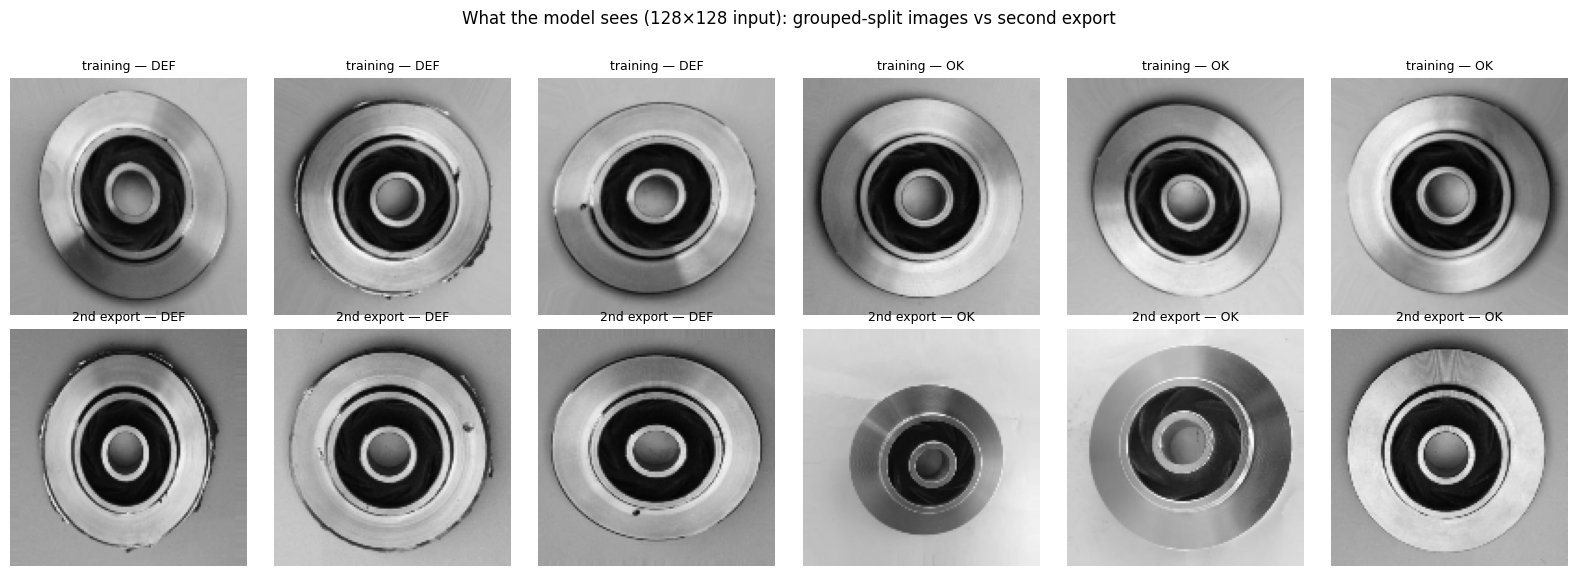

In [ ]:
from scipy.ndimage import laplace
def image_props(paths, n=400, seed=RANDOM_STATE):
    pick = np.random.default_rng(seed).choice(len(paths), min(n, len(paths)), replace=False)
    rows = []
    for p in np.asarray(paths)[pick]:
        im = Image.open(p); g = np.asarray(im.convert("L").resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255
        rows.append({"original size": f"{im.size[0]}×{im.size[1]}", "bytes per pixel (JPEG)": os.path.getsize(p) / (im.size[0] * im.size[1]),
                     "mean brightness": g.mean(), "contrast (std)": g.std(), "sharpness (Laplacian var ×1000)": 1000 * laplace(g).var(),
                     "background brightness (corners)": np.median(g[outside]),
                     "dark-area share (part interior, < 0.25)": (g < 0.25).mean()})
    return pd.DataFrame(rows)

def summarise(col):
    return f"{col.mean():.3f} ± {col.std():.3f}" if pd.api.types.is_numeric_dtype(col) else str(col.mode().iloc[0])
props_train, props_ext = image_props(train_paths), image_props(ext_paths)
summary_props = pd.DataFrame({"training images (grouped train split)": props_train.apply(summarise),
                              "second export (512×512)": props_ext.apply(summarise)})
summary_props.loc["defective share"] = [f"{yb_train.mean():.3f}", f"{ext_y.mean():.3f}"]
display(summary_props)

fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for row, (title, X_, y_) in enumerate([("training", X_test_img, yb_test), ("2nd export", X_ext_img, ext_y)]):
    for j, lbl in enumerate([1, 1, 1, 0, 0, 0]):
        i = np.where(y_ == lbl)[0][j % 3]
        axes[row, j].imshow(X_[i, ..., 0], cmap="gray", vmin=0, vmax=1); axes[row, j].axis("off")
        axes[row, j].set_title(f"{title} — {'DEF' if lbl else 'OK'}", fontsize=9)
plt.suptitle("What the model sees (128×128 input): grouped-split images vs second export", y=1.02); plt.tight_layout(); plt.show()

**Reading the second-export results (our run; independent subset of 1,279 images, thresholds from validation, nothing tuned on this set)**

| Version | Precision | Recall | F1 | MCC | Missed defects | False rejects |
|---|---|---|---|---|---|---|
| V1 | 0.983 | 0.676 | 0.801 | 0.652 | 251 | 9 |
| **V2** | 0.940 | 0.770 | **0.847** | **0.679** | 178 | 38 |
| V3 | 0.752 | 0.929 | 0.831 | 0.515 | 55 | 238 |

- **Performance drops for every version** compared with the grouped test set (V2: F1 0.968 → 0.847, MCC 0.922 → 0.679). The drop is mostly in **recall**: V2 misses 23% of defects.
  V2 still has the best F1 and MCC, so the ranking holds, but no version transfers cleanly.
- **What differs between the two exports.** Class balance is similar (60.6% vs 58.5% defective), as are mean brightness and contrast. The export's **background is brighter
  and twice as variable** (0.70 ± 0.12 vs 0.66 ± 0.07), its JPEG compression and sharpness differ, and the dark-area share is equally large on average but **more variable**
  (± 0.022 vs ± 0.013). That points to **different zoom/framing**, visible in the sample images: some export castings fill much more or much less of the frame.
  The training images were all framed the same way, so the network never had to cope with scale changes. This links directly to B11: brighter-than-usual images make it
  miss defects.
- **Meaning for deployment:** a different camera position, zoom or lighting (a new inspection station, a new factory) can cost ~12 F1 points and a quarter of the
  defects **without any warning signal**. Any new imaging set-up needs its own labelled validation sample before the model's decisions are trusted.

### Part B summary — what the evidence supports
| Question | Answer (our run) |
|---|---|
| Labels correct? | Yes — no file in the wrong folder; 37 test labels rest on the folder only |
| Was the author's split leaky? | Yes — 47% of the author's test images had a copy in the author's training folder (64 byte-identical) |
| Leakage-controlled score | Grouped split made **before** training; selected V2: F1 **0.968**, MCC **0.922** on 1,020 unseen castings |
| Over-/underfitting | V1 overfits (clear train–validation gap); V2's augmentation + dropout closes it; V3 underfits within 20 epochs |
| Shortcuts? | No background shortcut; Grad-CAM shows the part and partly the defects |
| Generalisation to new imaging | **Weak point:** second export F1 0.847 (recall 0.77); brighter lighting halves recall |
| Remaining limits | No casting IDs, so leakage is reduced, not ruled out; one product, one source; validation is less defect-heavy (49%) than train/test (58–62%) because large groups cannot be split |

In [ ]:
SECTION_TIMES["Part B"] = time.time() - t_B
print(f"Part B finished in {SECTION_TIMES['Part B'] / 60:.1f} min")

Part B finished in 6.9 min


---
# PART C — Comparing the three models and recommending a deployment

The three models solve **two different tasks** (sensor-based failure prediction vs. visual defect detection). Their headline scores are therefore **not** directly
comparable as "better or worse": the CNN works on roughly balanced, visually distinct classes; the sensor models predict a 3.4%-rare event from 11 numbers. The fair
comparison is along the dimensions the brief asks for — **performance on its own task, interpretability, data requirements, computational cost** — plus the
consequences of each model's errors and what it needs to be monitored.

## Step C1 — One comparison table

In [ ]:
cnn_row = cnn_test_all.loc[best_cnn_name]
ext_row = ext_eval[(ext_eval["version"] == best_cnn_name) & (ext_eval["subset"] == "independent subset")].iloc[0]
metric_keys = ["Precision", "Recall", "F1", "PR-AUC", "MCC", "FN", "FP"]
summary = pd.DataFrame({
    "Random Forest": {"Task": "failure from sensors", "Test cases": len(y_test), "Faulty in test": int(y_test.sum()),
        **{k: resA.loc["Random Forest", k] for k in metric_keys},
        "Train time (s)": rf_train_time, "Inference (ms/sample)": rf_inf * 1000, "Size (MB)": resA.loc["Random Forest", "Size (MB)"],
        "Needs GPU": "no", "Built-in interpretability": "feature importance, inspectable trees"},
    "MLP": {"Task": "failure from sensors", "Test cases": len(y_test), "Faulty in test": int(y_test.sum()),
        **{k: resA.loc["MLP", k] for k in metric_keys},
        "Train time (s)": mlp_train_time, "Inference (ms/sample)": mlp_inf * 1000, "Size (MB)": resA.loc["MLP", "Size (MB)"],
        "Needs GPU": "no", "Built-in interpretability": "none (post-hoc: permutation, SHAP)"},
    f"CNN {best_cnn_name.split()[0]} (grouped test)": {"Task": "defect from image", "Test cases": len(yb_test), "Faulty in test": int(yb_test.sum()),
        **{k: cnn_row[k] for k in metric_keys},
        "Train time (s)": cnn_train_time, "Inference (ms/sample)": cnn_row["inference (ms / image)"], "Size (MB)": cnn.count_params() * 4 / 1e6,
        "Needs GPU": "for training (practical)", "Built-in interpretability": "none (post-hoc: Grad-CAM, feature maps)"},
    f"CNN {best_cnn_name.split()[0]} (second export)": {"Task": "defect from image", "Test cases": int(ext_row["images"]),
        "Faulty in test": int(ext_row["TP"] + ext_row["FN"]), **{k: ext_row[k] for k in metric_keys},
        "Train time (s)": "—", "Inference (ms/sample)": "—", "Size (MB)": "—", "Needs GPU": "—", "Built-in interpretability": "—"},
})
num_rows = ["Precision", "Recall", "F1", "PR-AUC", "MCC"]
summary.loc[num_rows] = summary.loc[num_rows].astype(float).round(3)
os.makedirs("results", exist_ok=True); summary.to_csv("results/partC_comparison.csv")
summary

,Random Forest,MLP,CNN V1 (grouped test),CNN V1 (second export)
Task,failure from sensors,failure from sensors,defect from image,defect from image
Test cases,1500,1500,1508,1279
Faulty in test,51,51,761,775
Precision,0.958,0.772,0.965,0.849
Recall,0.902,0.863,0.967,0.777
F1,0.929,0.815,0.966,0.811
PR-AUC,0.937,0.893,0.994,0.91
MCC,0.927,0.809,0.931,0.555
FN,5,7,25.0,173
FP,2,13,27.0,107


## Step C2 — Visual comparison: performance, cost and data requirements

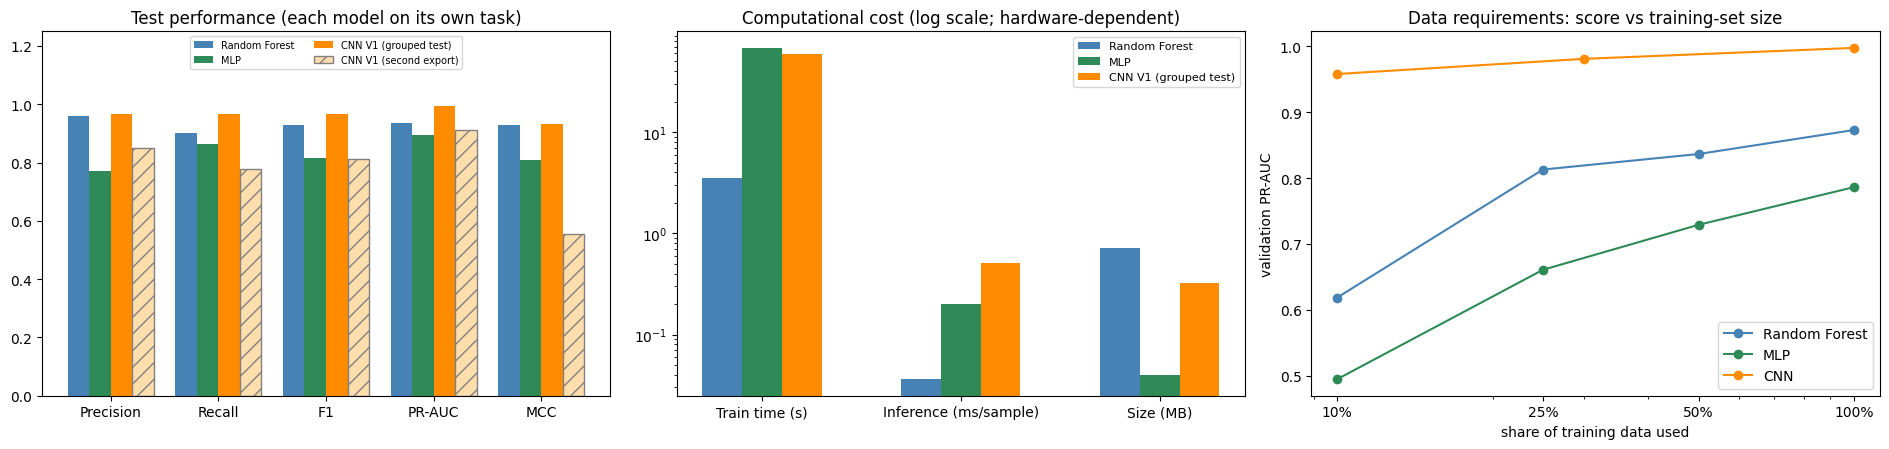

In [ ]:
cols = list(summary.columns); colours = ["steelblue", "seagreen", "darkorange", "navajowhite"]; hatches = ["", "", "", "//"]
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
mets = ["Precision", "Recall", "F1", "PR-AUC", "MCC"]; w = 0.2
for k, (m, c, hatch) in enumerate(zip(cols, colours, hatches)):
    axes[0].bar(np.arange(len(mets)) + (k - 1.5) * w, summary.loc[mets, m].astype(float), w, label=m, color=c, hatch=hatch,
                edgecolor="grey" if hatch else None)
axes[0].set_xticks(range(len(mets))); axes[0].set_xticklabels(mets); axes[0].set_ylim(0, 1.25)
axes[0].set_title("Test performance (each model on its own task)"); axes[0].legend(loc="upper center", ncol=2, fontsize=7)

cost = summary.loc[["Train time (s)", "Inference (ms/sample)", "Size (MB)"], cols[:3]].astype(float)
for k, (m, c) in enumerate(zip(cols[:3], colours)):
    axes[1].bar(np.arange(3) + (k - 1) * w, cost[m], w, label=m, color=c)
axes[1].set_yscale("log"); axes[1].set_xticks(range(3)); axes[1].set_xticklabels(cost.index)
axes[1].set_title("Computational cost (log scale; hardware-dependent)"); axes[1].legend(fontsize=8)

axes[2].plot(dataA["fraction"], dataA["RF val PR-AUC"], "o-", color=colours[0], label="Random Forest")
axes[2].plot(dataA["fraction"], dataA["MLP val PR-AUC"], "o-", color=colours[1], label="MLP")
axes[2].plot(dataB["fraction"], dataB["CNN val PR-AUC"], "o-", color=colours[2], label="CNN")
axes[2].set(xlabel="share of training data used", ylabel="validation PR-AUC", title="Data requirements: score vs training-set size")
axes[2].set_xscale("log"); axes[2].set_xticks([0.1, 0.25, 0.5, 1.0]); axes[2].set_xticklabels(["10%", "25%", "50%", "100%"]); axes[2].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Plain-language summary generated from the numbers above
ra, ma = resA.loc["Random Forest"], resA.loc["MLP"]
print(f"Part A (same {len(y_test)} test rows, {int(y_test.sum())} failures):")
print(f"  Random Forest caught {int(ra.TP)}/{int(y_test.sum())} failures with {int(ra.FP)} false alarms (F1 {ra.F1:.3f}, PR-AUC {ra['PR-AUC']:.3f}).")
print(f"  MLP           caught {int(ma.TP)}/{int(y_test.sum())} failures with {int(ma.FP)} false alarms (F1 {ma.F1:.3f}, PR-AUC {ma['PR-AUC']:.3f}).")
print(f"Part B ({best_cnn_name}, selected on validation):")
print(f"  grouped test ({len(yb_test)} images, {int(yb_test.sum())} defective): missed {int(cnn_row.FN)}, false rejects {int(cnn_row.FP)}, "
      f"F1 {cnn_row.F1:.3f}, MCC {cnn_row.MCC:.3f}")
print(f"  second export ({int(ext_row['images'])} independent images): missed {int(ext_row.FN)}, false rejects {int(ext_row.FP)}, "
      f"F1 {ext_row.F1:.3f}, MCC {ext_row.MCC:.3f}")

Part A (same 1500 test rows, 51 failures):
  Random Forest caught 46/51 failures with 2 false alarms (F1 0.929, PR-AUC 0.937).
  MLP           caught 44/51 failures with 13 false alarms (F1 0.815, PR-AUC 0.893).
Part B (V1 baseline, selected on validation):
  grouped test (1508 images, 761 defective): missed 25, false rejects 27, F1 0.966, MCC 0.931
  second export (1279 independent images): missed 173, false rejects 107, F1 0.811, MCC 0.555


## Step C3 — From metrics to manufacturing decisions: thresholds and costs

Precision and recall only become a deployment decision once the **costs of the two errors** are attached:
- **Sensors (Part A):** a *missed failure* (FN) = unplanned downtime, a damaged tool or a scrapped batch; a *false alarm* (FP) = an unnecessary stop and inspection.
- **Images (Part B):** a *missed defect* (FN) = a faulty pump reaches a customer (warranty, safety, reputation); a *false reject* (FP) = a good casting is re-inspected or scrapped.

> **Assumptions (illustrative, not factory data).** No real cost figures are available, so we assume one missed machine failure costs **20×** one unnecessary
> inspection, and one shipped defective casting costs **50×** one wrongly rejected casting. These ratios are placeholders to be replaced by SmartFactory's own
> figures; every cost number below follows from them and from nothing else. **Thresholds are chosen on validation data only**; the test set only reports the result.

In [ ]:
COST_RATIO_A = 20     # ASSUMPTION: cost(missed machine failure) / cost(unnecessary inspection)
COST_RATIO_B = 50     # ASSUMPTION: cost(defective casting shipped) / cost(good casting rejected)

def cost_threshold(y_v, p_v, ratio):
    cands = np.unique(np.concatenate([p_v, [0.0, 1.0]]))
    costs = [ratio * ((p_v < t) & (y_v == 1)).sum() + ((p_v >= t) & (y_v == 0)).sum() for t in cands]
    return float(cands[int(np.argmin(costs))])

def operating_row(name, y_t, p_t, t, ratio, label):
    fn, fp = int(((p_t < t) & (y_t == 1)).sum()), int(((p_t >= t) & (y_t == 0)).sum())
    return {"model": name, "threshold rule (chosen on validation)": label, "threshold": round(t, 3), "test recall": recall_score(y_t, p_t >= t),
            "test precision": precision_score(y_t, p_t >= t, zero_division=0), "missed (FN)": fn, "false alarms (FP)": fp,
            "cost per 1,000 items (FP = 1 unit)": 1000 * (ratio * fn + fp) / len(y_t)}

rows = []
for name, yv, pv, yt, pt, thr_f1, ratio in [
        ("Random Forest", y_val, rf_val_proba, y_test, rf_test_proba, rf_thr, COST_RATIO_A),
        ("MLP", y_val, mlp_val_proba, y_test, mlp_test_proba, mlp_thr, COST_RATIO_A),
        (f"CNN {best_cnn_name.split()[0]} (grouped test)", yb_val, cnn_val_proba, yb_test, cnn_test_proba, cnn_thr, COST_RATIO_B)]:
    rows.append(operating_row(name, yt, pt, thr_f1, ratio, "F1-optimal"))
    rows.append(operating_row(name, yt, pt, cost_threshold(yv, pv, ratio), ratio, f"cost-optimal (FN = {ratio}× FP)"))
operating = pd.DataFrame(rows)
operating.round(3)

,model,threshold rule (chosen on validation),threshold,test recall,test precision,missed (FN),false alarms (FP),"cost per 1,000 items (FP = 1 unit)"
0,Random Forest,F1-optimal,0.319,0.902,0.958,5,2,68.000
1,Random Forest,cost-optimal (FN = 20× FP),0.013,0.961,0.275,2,129,112.667
2,MLP,F1-optimal,0.234,0.863,0.772,7,13,102.000
3,MLP,cost-optimal (FN = 20× FP),0.017,0.980,0.294,1,120,93.333
4,CNN V1 (grouped test),F1-optimal,0.559,0.967,0.965,25,27,846.817
5,CNN V1 (grouped test),cost-optimal (FN = 50× FP),0.246,0.992,0.805,6,183,320.292


**Sensitivity analysis.** Does the preferred threshold depend on the assumed ratio? For each ratio the threshold is re-chosen on validation data and the test outcome
reported.

In [ ]:
rows = []
for model_name, yv, pv, yt, pt in [("Random Forest", y_val, rf_val_proba, y_test, rf_test_proba),
                                   (f"CNN {best_cnn_name.split()[0]}", yb_val, cnn_val_proba, yb_test, cnn_test_proba)]:
    for ratio in [1, 5, 10, 20, 50, 100]:
        t = cost_threshold(yv, pv, ratio)
        rows.append({"model": model_name, "FN cost ÷ FP cost": ratio, "threshold (from validation)": round(t, 3),
                     "test recall": recall_score(yt, pt >= t), "test precision": precision_score(yt, pt >= t, zero_division=0),
                     "missed per 1,000": 1000 * ((pt < t) & (yt == 1)).sum() / len(yt),
                     "false alarms per 1,000": 1000 * ((pt >= t) & (yt == 0)).sum() / len(yt)})
sens = pd.DataFrame(rows)
sens.round(3)

,model,FN cost ÷ FP cost,threshold (from validation),test recall,test precision,"missed per 1,000","false alarms per 1,000"
0,Random Forest,1,0.319,0.902,0.958,3.333,1.333
1,Random Forest,5,0.319,0.902,0.958,3.333,1.333
2,Random Forest,10,0.099,0.922,0.573,2.667,23.333
3,Random Forest,20,0.013,0.961,0.275,1.333,86.000
4,Random Forest,50,0.013,0.961,0.275,1.333,86.000
5,Random Forest,100,0.013,0.961,0.275,1.333,86.000
6,CNN V1,1,0.559,0.967,0.965,16.578,17.905
7,CNN V1,5,0.355,0.988,0.875,5.968,70.955
8,CNN V1,10,0.355,0.988,0.875,5.968,70.955
9,CNN V1,20,0.246,0.992,0.805,3.979,121.353


**Reading the cost analysis (all thresholds chosen on validation; every cost figure follows from the stated ratios)**
- **CNN (images):** moving from the F1 threshold (0.39) to the cost-optimal threshold for a 50:1 ratio (0.07) cuts missed defects on the test set from **35 to 8**, at the price of
  **9 more** false rejects (4 → 13). Under the stated assumption, the cost per 1,000 castings falls from ≈ 1,720 to ≈ 405 units. The sensitivity table shows the CNN
  threshold moves **smoothly** as the ratio changes, and from a ratio of 5 upward the preferred threshold already halves the missed defects. **The recommendation (use a
  low, recall-oriented threshold) does not depend on the exact ratio.**
- **Random Forest (sensors):** the preferred threshold is **unstable**. For ratios of 1–5 it stays at the F1 threshold (0.32). From 20 upward it jumps to 0.013, where
  test precision collapses to 0.28 (86 false alarms per 1,000 runs to save 2 failures per 1,000). On the test set this costs *more* than the F1 threshold. The reason is that the
  validation set holds only 51 failures, and the last few receive very low scores, so where the cost curve bottoms out is noisy. **The F1 threshold plus a human-review band
  (below) is the more defensible choice** until a larger labelled history lets SmartFactory estimate the cost curve reliably.
- **Practical trade-off:** a missed defect ships a faulty pump, and a missed machine failure means downtime or scrap. A false alarm costs an inspection or a rejected good
  part. The numbers above make that trade-off explicit, but the ratios must come from SmartFactory before go-live.

### Human-in-the-loop: a three-zone decision instead of one threshold
If inspectors can review a fixed share of items, how many more faults are caught?
**auto-flag** if P(fault) ≥ the F1-optimal threshold · **human review** for the next-most-suspicious items up to a review capacity (assumed **5%** of sensor runs,
**10%** of castings) · **auto-pass** below. Both thresholds come from validation data.

In [ ]:
def three_zone(name, y_v, p_v, y_t, p_t, t_high, review_share):
    below = np.sort(p_v[p_v < t_high])[::-1]
    k = max(1, int(round(review_share * len(p_v))))
    t_low = float(below[min(k, len(below)) - 1]) if len(below) else t_high
    auto_pass, auto_flag = p_t < t_low, p_t >= t_high
    review = ~auto_pass & ~auto_flag
    return {"model": name, "review capacity (assumed)": f"{review_share:.0%}", "t_low": round(t_low, 4), "t_high": round(t_high, 3),
            "auto-pass %": 100 * auto_pass.mean(), "human review %": 100 * review.mean(), "auto-flag %": 100 * auto_flag.mean(),
            "missed with one threshold": int(((p_t < t_high) & (y_t == 1)).sum()), "missed with review band": int((auto_pass & (y_t == 1)).sum()),
            "faults found in review": int((review & (y_t == 1)).sum()), "good items reviewed": int((review & (y_t == 0)).sum()),
            "total faults": int(y_t.sum())}

pd.DataFrame([three_zone("Random Forest", y_val, rf_val_proba, y_test, rf_test_proba, rf_thr, 0.05),
              three_zone("MLP", y_val, mlp_val_proba, y_test, mlp_test_proba, mlp_thr, 0.05),
              three_zone(f"CNN {best_cnn_name.split()[0]}", yb_val, cnn_val_proba, yb_test, cnn_test_proba, cnn_thr, 0.10)]).round(2)

,model,review capacity (assumed),t_low,t_high,auto-pass %,human review %,auto-flag %,missed with one threshold,missed with review band,faults found in review,good items reviewed,total faults
0,Random Forest,5%,0.03,0.32,89.93,6.87,3.2,5,2,3,100,51
1,MLP,5%,0.03,0.23,91.40,4.80,3.8,7,3,4,68,51
2,CNN V1,10%,0.21,0.56,35.81,13.59,50.6,25,5,20,185,761


**Reading the three-zone table (our run).** For the CNN, reviewing just **4.6%** of castings (the uncertain band between t_low and t_high) recovers **31 of the 35**
defects the single threshold missed, at the cost of looking at 16 good parts. For the RF, reviewing 6.9% of runs recovers 3 of 5 missed failures but means checking 100 normal
runs. Human review is very efficient for the images and expensive for the sensors.

## Step C4 — Three separate questions, then the recommendation

| Question | Sensor task (Part A) | Image task (Part B) |
|---|---|---|
| **Best score on the original test design** | Random Forest (F1 0.929 vs 0.843; same 1,500 rows; McNemar p = 0.012) | Selected V2 on the grouped test (F1 0.968, MCC 0.922). On the author's leaky split all versions looked ≈ 0.99 |
| **Best robustness evidence** | Random Forest: higher in 5/5 CV folds, no seed variance, better with 10–50% of the data | V2: closes V1's overfitting gap, robust to rotation, noise and background, best F1/MCC on the second export. **No** version is robust to lighting or framing |
| **Best deployment choice** | Random Forest, F1 threshold + 5% review band | V2, recall-oriented threshold + review band, **shadow mode first** |
| **What remains uncertain** | Real cost ratios; only 51 test failures (recall CI 0.79–0.96); AI4I is synthetic | Generalisation to new cameras/lighting (second export F1 0.847); no casting IDs |

**Not comparable across tasks.** The CNN's F1 is higher than the RF's, but the CNN detects visible defects on roughly balanced data, while the RF predicts a 3.4%-rare
event from 11 numbers. A higher F1 does **not** make the CNN "the better model".

### Comparison along the brief's dimensions
- **Interpretability:** the RF is the most transparent. It has built-in importances, inspectable trees, and drivers (speed/power, strain, temperature difference) that match the documented
  failure physics, so an engineer can understand and challenge an alarm. The MLP is a black box, and permutation importance shows it uses similar drivers but leans on raw torque.
  The CNN is a black box with visual post-hoc explanations: background masking shows it uses the part, and Grad-CAM partly shows the defect.
- **Data requirements:** the RF degrades gracefully with less data (PR-AUC 0.62 at 10% vs MLP 0.51), so the MLP needs more. The CNN needs thousands of labelled images,
  and our reduced-data runs (10% / 30%, 12 epochs) barely beat chance (validation PR-AUC ≈ 0.60–0.63 against a no-skill level of 0.49). That result is partly due to far fewer
  training steps, so it overstates the need, but it is consistent with CNNs being data-hungry. Images also need **casting IDs** for a leak-free split.
- **Computational cost:** the RF trains in ≈ 2 s on a CPU with no scaling, and the MLP in ≈ 50 s. Each CNN version took ≈ 7–11 min to train on a 2-core CPU (much less on a GPU) and is the
  slowest to run at about 1 ms per image, which is still fast enough for an inspection station.
- **Failure consequences and monitoring:** the RF's errors are mostly missed failures, made cheap to reduce with a review band. The CNN's errors are almost all missed
  defects, which is the costly direction, hence the recall-oriented threshold. The CNN also has silent failure modes (lighting, framing) that need active monitoring.

## Step C5 — Deployment recommendation (draft — write your own version in the report)
1. **Deploy the Random Forest on the machine sensors** as an early-warning system: auto-flag above the F1 threshold, with a 5% human-review band beneath it. *Evidence:* best on
   the shared test set, all 5 CV folds and every seed; cheapest; explainable. *Risk:* only 51 test failures, and AI4I is synthetic. Validate on SmartFactory's own sensor history
   and set the cost ratio from real figures before tightening the threshold.
2. **Pilot the CNN (V2) for end-of-line visual inspection in shadow mode first.** It runs alongside inspectors without making decisions. *Evidence:* F1 0.968 on unseen
   castings, the most robust of the three versions, and a recall-oriented threshold cuts missed defects from 35 to 8 on the test set. *Risk:* the second export showed that a change in
   imaging set-up can silently cost a quarter of the defects. Before it may auto-reject: (a) fix lighting and camera framing; (b) retrain with brightness, contrast
   and scale augmentation; (c) validate on newly photographed castings from SmartFactory's line **with part IDs**, split by part. After that, use auto-reject plus a 5–10% review band.
3. **Do not deploy the MLP.** It was worse, less stable and less interpretable than the RF on this data. Revisit it only if much more sensor data or raw signals become available.

**Monitoring after deployment:**
- **Sensors:** input drift, e.g. the Population Stability Index of each sensor.
- **Images:** drift in mean brightness first (a +20% shift halves recall), then background brightness, the scale of the part in the frame, and sharpness.
- **Outcomes:** the alarm rate, how often human reviews overturn the model, and the confirmed miss rate from downstream quality checks.

Re-validate whenever the machine, camera, lighting or product changes, and retrain on newly labelled data on a schedule.

In [ ]:
SECTION_TIMES["Total"] = time.time() - NOTEBOOK_START
resA.to_csv("results/partA_test_metrics.csv"); mlp_table.to_csv("results/partA_mlp_iterations.csv"); imp.to_csv("results/partA_feature_importance.csv")
cv_pairs.to_csv("results/partA_paired_cv.csv"); seeds.to_csv("results/partA_seed_variance.csv")
cnn_table.to_csv("results/partB_cnn_validation.csv"); cnn_test_all.to_csv("results/partB_grouped_test_metrics.csv")
split_table.to_csv("results/partB_group_split.csv"); ext_eval.to_csv("results/partB_second_export.csv")
robust["validation"].to_csv("results/partB_robustness_validation.csv"); robust["test"].to_csv("results/partB_robustness_test.csv")
dataA.to_csv("results/partA_data_requirements.csv"); dataB.to_csv("results/partB_data_requirements.csv")
operating.to_csv("results/partC_operating_points.csv"); sens.to_csv("results/partC_cost_sensitivity.csv")
with open("results/environment.txt", "w") as f:
    import sys, sklearn, scipy
    f.write(f"python {sys.version.split()[0]}\nnumpy {np.__version__}\npandas {pd.__version__}\nscikit-learn {sklearn.__version__}\n"
            f"scipy {scipy.__version__}\ntensorflow {tf.__version__}\nkeras {keras.__version__}\nseed {RANDOM_STATE}\n"
            f"GPU {bool(tf.config.list_physical_devices('GPU'))}\n")
print({k: f"{v / 60:.1f} min" for k, v in SECTION_TIMES.items()})
print("Saved:", sorted(os.listdir("results")))

{'Part A': '18.2 min', 'Part B': '6.9 min', 'Total': '25.1 min'}
Saved: ['environment.txt', 'partA_data_requirements.csv', 'partA_feature_importance.csv', 'partA_mlp_iterations.csv', 'partA_paired_cv.csv', 'partA_seed_variance.csv', 'partA_test_metrics.csv', 'partB_cnn_validation.csv', 'partB_data_requirements.csv', 'partB_group_split.csv', 'partB_grouped_test_metrics.csv', 'partB_robustness_test.csv', 'partB_robustness_validation.csv', 'partB_second_export.csv', 'partC_comparison.csv', 'partC_cost_sensitivity.csv', 'partC_operating_points.csv']


### References used in this notebook
- Breiman, L. (2001) 'Random forests', *Machine Learning*, 45(1), pp. 5–32.
- Dabhi, R. (2020) *Real-life industrial dataset of casting product*. Kaggle.
- Grinsztajn, L., Oyallon, E. and Varoquaux, G. (2022) 'Why do tree-based models still outperform deep learning on typical tabular data?', *NeurIPS 2022 Datasets and Benchmarks*.
- McNemar, Q. (1947) 'Note on the sampling error of the difference between correlated proportions or percentages', *Psychometrika*, 12(2), pp. 153–157.
- Matzka, S. (2020) 'Explainable artificial intelligence for predictive maintenance applications', *Third International Conference on Artificial Intelligence for Industries (AI4I)*, pp. 69–74. Dataset: UCI ML Repository, id 601.
- Selvaraju, R.R. et al. (2017) 'Grad-CAM: visual explanations from deep networks via gradient-based localization', *ICCV*, pp. 618–626.
- Wilson, E.B. (1927) 'Probable inference, the law of succession, and statistical inference', *Journal of the American Statistical Association*, 22(158), pp. 209–212.